In [1]:
import os

print("Direktori notebook:", os.getcwd())
print("Folder workspace tersedia:", os.path.isdir("/workspace/USP5_MANN_53"))
print("Folder Aliya tersedia:", os.path.isdir("/data/Aliya"))

Direktori notebook: /data/Aliya/model 
Folder workspace tersedia: True
Folder Aliya tersedia: True


In [2]:
import os

os.chdir("/workspace/USP5_MANN_53")

print("Direktori kerja sekarang:", os.getcwd())

Direktori kerja sekarang: /workspace/USP5_MANN_53


In [3]:
import pandas as pd

url = "https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv"

df = pd.read_csv(url)

print("=== DATASET USP5 MANN ===")
print("Jumlah baris:", len(df))
print("Jumlah kolom:", len(df.columns))

print("\n=== NAMA KOLOM ===")
print(df.columns.tolist())

print("\n=== 5 DATA PERTAMA ===")
display(df.head())

=== DATASET USP5 MANN ===
Jumlah baris: 53
Jumlah kolom: 4

=== NAMA KOLOM ===
['Molecule ChEMBL ID', 'Smiles', 'Standard Value', 'pKd']

=== 5 DATA PERTAMA ===


,Molecule ChEMBL ID,Smiles,Standard Value,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,130000,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,45000,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,23000,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,79000,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,150000,3.823909


In [4]:
import os

print("Folder kerja:", os.getcwd())
print("Isi folder:", os.listdir("/workspace/USP5_MANN_53"))
print("Notebook aktif tidak otomatis tersimpan di folder kerja Python.")

Folder kerja: /workspace/USP5_MANN_53
Isi folder: []
Notebook aktif tidak otomatis tersimpan di folder kerja Python.


# USP5 Mann 53 — Tanimoto Non-Linear Blend

Adaptasi dari `USP5_NonLinear_Model.ipynb` untuk 53 senyawa dari artikel Mann. 
**Pendekatan:** SVR kernel Tanimoto (Morgan+MACCS) + RF Morgan+MACCS + RF MACCS, digabungkan dengan bobot rata-rata sama.

In [6]:
import os, sys, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, rdBase
from rdkit.Chem import rdFingerprintGenerator, MACCSkeys
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import KFold, GroupKFold
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib

warnings.filterwarnings('ignore', category=FutureWarning)
OUT = Path('/workspace/USP5_MANN_53')
OUT.mkdir(parents=True, exist_ok=True)
print('Python:', sys.version.split()[0], '| RDKit:', rdBase.rdkitVersion, '| Folder:', OUT)

Python: 3.10.12 | RDKit: 2026.09.1 | Folder: /workspace/USP5_MANN_53


In [7]:
url = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv'
df = pd.read_csv(url)
df.columns = df.columns.str.strip()
required = {'Molecule ChEMBL ID', 'Smiles', 'Standard Value', 'pKd'}
assert required.issubset(df.columns), f'Kolom belum lengkap: {required - set(df.columns)}'
assert len(df) == 53, f'Jumlah data berubah: {len(df)} (harap cek dataset)'
df['pKd'] = pd.to_numeric(df['pKd'], errors='coerce')
df['Standard Value'] = pd.to_numeric(df['Standard Value'], errors='coerce')
assert df[['pKd','Smiles','Standard Value']].notna().all().all(), 'Ada nilai kosong'
assert df['Standard Value'].gt(0).all(), 'Kd harus positif'
err = np.max(np.abs(df['pKd'] - (9 - np.log10(df['Standard Value']))))
assert err < 0.002, f'Perlu cek satuan Kd/pKd: selisih maksimum={err}'
mols = [Chem.MolFromSmiles(s) for s in df['Smiles']]
assert all(m is not None for m in mols), 'SMILES tidak valid'
can = [Chem.MolToSmiles(m, canonical=True) for m in mols]
assert len(set(can)) == len(can), 'SMILES kanonik duplikat; periksa dulu sebelum CV'
groups = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
y = df['pKd'].to_numpy(dtype=float)
print('Senyawa:', len(df), '| Scaffold unik:', len(set(groups)))
print('pKd min/median/max:', round(y.min(),3), round(np.median(y),3), round(y.max(),3))
print('Rentang selisih pKd dari Kd:', round(err,6))
print('Catatan: dataset tidak memiliki label assay -> efek kedua assay tidak dapat diuji langsung.')
display(df.head())

Senyawa: 53 | Scaffold unik: 25
pKd min/median/max: 3.569 4.377 5.553
Rentang selisih pKd dari Kd: 0.0
Catatan: dataset tidak memiliki label assay -> efek kedua assay tidak dapat diuji langsung.


,Molecule ChEMBL ID,Smiles,Standard Value,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,130000,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,45000,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,23000,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,79000,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,150000,3.823909


In [8]:
# Fitur dasar dihitung dari SMILES tanpa target pKd; seleksi bit dilakukan hanya pada data training tiap fold.
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
F = np.stack([gen.GetFingerprintAsNumPy(m) for m in mols]).astype(np.float32)
M = np.stack([np.asarray(MACCSkeys.GenMACCSKeys(m), dtype=np.float32) for m in mols])

def tani(a, b):
    cross = a @ b.T
    denom = a.sum(axis=1)[:, None] + b.sum(axis=1)[None, :] - cross
    return cross / np.maximum(denom, 1e-10)

class MannBlend:
    def __init__(self, n_estimators=200, seed=0):
        self.n_estimators, self.seed = n_estimators, seed
    def fit(self, f, m, yy):
        # Semua pemilihan fitur dihitung pada TRAINING saja (mencegah data leakage).
        self.fm = f.sum(axis=0) >= max(2, int(np.ceil(.05 * len(yy))))
        self.mm = m.var(axis=0) > 0
        a = np.column_stack((f[:, self.fm], m[:, self.mm]))
        b = m[:, self.mm]
        if a.shape[1] == 0 or b.shape[1] == 0:
            raise ValueError('Tidak cukup fitur informatif pada training fold')
        self.a_train = a
        self.svr = SVR(kernel='precomputed', C=5.0, epsilon=0.05).fit(tani(a,a), yy)
        self.rf1 = RandomForestRegressor(n_estimators=self.n_estimators, random_state=self.seed, n_jobs=-1).fit(a, yy)
        self.rf2 = RandomForestRegressor(n_estimators=self.n_estimators, random_state=self.seed, n_jobs=-1).fit(b, yy)
        return self
    def predict_members(self, f, m):
        a = np.column_stack((f[:,self.fm], m[:,self.mm]))
        b = m[:,self.mm]
        return np.column_stack((self.svr.predict(tani(a,self.a_train)), self.rf1.predict(a), self.rf2.predict(b)))
    def predict(self, f, m):
        return self.predict_members(f,m).mean(axis=1)

def make_folds(kind, seed):
    if kind == 'random':
        return list(KFold(n_splits=5, shuffle=True, random_state=seed).split(y))
    # GroupKFold memastikan scaffold yang sama tidak terbagi antara train dan test.
    return list(GroupKFold(n_splits=5, shuffle=True, random_state=seed).split(F, y, groups))

def evaluate(kind, seed):
    pred = np.full(len(y), np.nan)
    members = np.full((len(y),3), np.nan)
    fold_id = np.full(len(y), -1)
    folds = make_folds(kind, seed)
    for i, (tr, te) in enumerate(folds):
        assert len(tr)>0 and len(te)>0
        if kind == 'scaffold':
            assert not (set(groups[tr]) & set(groups[te])), 'Scaffold overlap!'
        model = MannBlend(seed=seed).fit(F[tr], M[tr], y[tr])
        members[te] = model.predict_members(F[te], M[te])
        pred[te] = members[te].mean(axis=1)
        fold_id[te] = i+1
    assert np.isfinite(pred).all()
    result = {'metode':kind, 'seed':seed, 'R2':r2_score(y,pred),
              'RMSE':np.sqrt(mean_squared_error(y,pred)), 'MAE':mean_absolute_error(y,pred)}
    return result, pred, members, fold_id

print('Jumlah fitur mentah:', F.shape[1], 'Morgan +', M.shape[1], 'MACCS')

Jumlah fitur mentah: 1024 Morgan + 167 MACCS


In [9]:
# Evaluasi berulang (3 seed x 5-fold) dengan hyperparameter tetap dari notebook dosen.
# Tidak melakukan tuning berdasarkan hasil test fold.
SEEDS = [42, 123, 2026]
rows = []
all_predictions = []
for kind in ['random','scaffold']:
    for seed in SEEDS:
        score, pred, members, fold_id = evaluate(kind, seed)
        rows.append(score)
        tmp = pd.DataFrame({
            'Molecule ChEMBL ID':df['Molecule ChEMBL ID'], 'Smiles':df['Smiles'],
            'pKd_eksperimen':y, 'pKd_prediksi':pred, 'residual':y-pred,
            'metode':kind, 'seed':seed, 'fold':fold_id,
            'pred_SVR_Tanimoto':members[:,0], 'pred_RF_FPM':members[:,1], 'pred_RF_MACCS':members[:,2]
        })
        all_predictions.append(tmp)
        print(f'{kind:8s} seed={seed}: R²={score["R2"]:.3f} | RMSE={score["RMSE"]:.3f} | MAE={score["MAE"]:.3f}')

scores = pd.DataFrame(rows)
preds = pd.concat(all_predictions, ignore_index=True)
summary = scores.groupby('metode')[['R2','RMSE','MAE']].agg(['mean','std']).round(4)
display(summary)
scores.to_csv(OUT/'hasil_per_seed_MANN53.csv', index=False)
preds.to_csv(OUT/'prediksi_OOF_MANN53.csv', index=False)
summary.to_csv(OUT/'ringkasan_CV_MANN53.csv')

random   seed=42: R²=0.358 | RMSE=0.369 | MAE=0.281
random   seed=123: R²=0.384 | RMSE=0.361 | MAE=0.279
random   seed=2026: R²=0.368 | RMSE=0.366 | MAE=0.278
scaffold seed=42: R²=0.265 | RMSE=0.395 | MAE=0.308
scaffold seed=123: R²=0.171 | RMSE=0.419 | MAE=0.321
scaffold seed=2026: R²=0.170 | RMSE=0.420 | MAE=0.323


R2            RMSE             MAE        
            mean     std    mean     std    mean     std
metode                                                  
random    0.3700  0.0132  0.3655  0.0038  0.2792  0.0016
scaffold  0.2019  0.0544  0.4113  0.0142  0.3175  0.0080

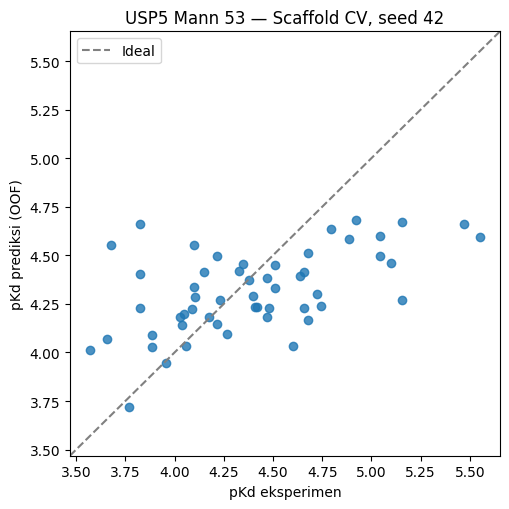

In [10]:
# Grafik pooled out-of-fold prediction pada satu seed scaffold CV (bukan independent test set)
p = preds.query("metode == 'scaffold' and seed == 42")
fig, ax = plt.subplots(figsize=(5.2, 5.2))
ax.scatter(p['pKd_eksperimen'],p['pKd_prediksi'], alpha=.8)
lims = [min(p['pKd_eksperimen'].min(),p['pKd_prediksi'].min())-.1,
        max(p['pKd_eksperimen'].max(),p['pKd_prediksi'].max())+.1]
ax.plot(lims, lims, '--', color='gray', label='Ideal')
ax.set(xlabel='pKd eksperimen', ylabel='pKd prediksi (OOF)', title='USP5 Mann 53 — Scaffold CV, seed 42', xlim=lims, ylim=lims)
ax.legend(); fig.tight_layout()
fig.savefig(OUT/'grafik_scaffold_MANN53.png', dpi=200)
plt.show()

In [11]:
# Latih model final pada seluruh 53 senyawa, setelah seluruh evaluasi CV selesai.
final_model = MannBlend(n_estimators=200, seed=42).fit(F, M, y)
joblib.dump({'model':final_model, 'training_smiles':df['Smiles'].tolist(),
             'training_pKd':y.tolist(), 'features':'Morgan radius 2 / 1024 bit + MACCS',
             'dataset':'USP5_MANN_53.csv', 'note':'Tidak mengukur perbedaan 2 assay'},
            OUT/'USP5_MANN53_Tanimoto_Blend.joblib')
print('Model tersimpan:', OUT/'USP5_MANN53_Tanimoto_Blend.joblib')
print('Seluruh hasil:')
for file in sorted(OUT.iterdir()):
    print(' -',file.name, f'({file.stat().st_size/1024:.1f} KB)')
print('PENTING: /workspace mungkin hilang saat reset. Unduh hasil penting ke komputer.')

Model tersimpan: /workspace/USP5_MANN_53/USP5_MANN53_Tanimoto_Blend.joblib
Seluruh hasil:
 - USP5_MANN53_Tanimoto_Blend.joblib (1925.1 KB)
 - grafik_scaffold_MANN53.png (91.0 KB)
 - hasil_per_seed_MANN53.csv (0.4 KB)
 - prediksi_OOF_MANN53.csv (57.4 KB)
 - ringkasan_CV_MANN53.csv (0.2 KB)
PENTING: /workspace mungkin hilang saat reset. Unduh hasil penting ke komputer.


# USP5 Mann 53 — ML Descriptor Ensemble

Adaptasi dari **`USP5_pKd_ML_Ensemble.ipynb`**, menggunakan data **53 senyawa Mann**. 
Tiga anggota asli: BayesianRidge (Morgan+MACCS), SVR linear (Morgan+MACCS), GradientBoosting (deskriptor+Morgan); prediksi dirata-ratakan.

In [12]:
import os, sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib
warnings.filterwarnings('ignore', category=FutureWarning)
OUT = Path('/workspace/USP5_MANN_53/ML_Ensemble')
OUT.mkdir(parents=True, exist_ok=True)
print('Python:',sys.version.split()[0], '| RDKit:',rdBase.rdkitVersion, '| Output:',OUT)

Python: 3.10.12 | RDKit: 2026.09.1 | Output: /workspace/USP5_MANN_53/ML_Ensemble


In [13]:
URL = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv'
df = pd.read_csv(URL)
df.columns = df.columns.str.strip()
required = {'Molecule ChEMBL ID','Smiles','Standard Value','pKd'}
assert required.issubset(df.columns), f'Kolom hilang: {required - set(df.columns)}'
assert len(df) == 53, f'Jumlah data berubah: {len(df)}'
df['pKd'] = pd.to_numeric(df['pKd'], errors='coerce')
df['Standard Value'] = pd.to_numeric(df['Standard Value'], errors='coerce')
assert df[['Smiles','pKd','Standard Value']].notna().all().all(), 'Data kosong ditemukan'
assert df['Standard Value'].gt(0).all(), 'Kd harus positif'
assert np.max(np.abs(df['pKd'].values - (9-np.log10(df['Standard Value'].values)))) < .002, 'Periksa satuan pKd dan Kd (diasumsikan nM)'
mols = [Chem.MolFromSmiles(s) for s in df['Smiles']]
assert all(m is not None for m in mols), 'Ada SMILES tidak valid'
assert len(set(Chem.MolToSmiles(m, canonical=True) for m in mols)) == len(mols), 'Ada SMILES duplikat'
y = df['pKd'].to_numpy(dtype=float)
groups = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
assert len(set(groups)) >= 5, 'Jumlah scaffold kurang dari 5 untuk 5-fold CV'
print('Senyawa:',len(y),'| scaffold unik:',len(set(groups)), '| pKd:',round(y.min(),3),'s.d.',round(y.max(),3))
print('Dua assay tidak dianalisis secara terpisah karena dataset ini tidak menyertakan label assay.')
display(df.head())

Senyawa: 53 | scaffold unik: 25 | pKd: 3.569 s.d. 5.553
Dua assay tidak dianalisis secara terpisah karena dataset ini tidak menyertakan label assay.


,Molecule ChEMBL ID,Smiles,Standard Value,pKd
0,CHEMBL5285743,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3C(=O)Cc4cc...,130000,3.886057
1,CHEMBL5290717,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(N3CCOCC3)CC2...,45000,4.346787
2,CHEMBL5285627,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3ccc(F)cc3)...,23000,4.638272
3,CHEMBL5274675,O=C(O)CNC(=O)c1ccc(S(=O)(=O)N2CCC(c3cccc(C(F)(...,79000,4.102373
4,CHEMBL5276984,Cn1cc(S(=O)(=O)N2CCC(c3ccccc3)CC2)cc1C(=O)NCC(...,150000,3.823909


In [14]:
# Blok fitur notebook dosen: deskriptor RDKit 2D, Morgan count r=2 1024, MACCS 167.
desc_names = [name for name, _ in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
DESC = np.asarray([calc.CalcDescriptors(m) for m in mols], dtype=float)
DESC[~np.isfinite(DESC)] = np.nan  # imputer di-fit hanya pada training fold
mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN = np.asarray([mgen.GetCountFingerprintAsNumPy(m) for m in mols], dtype=float)
MACCS = np.asarray([np.asarray(MACCSkeys.GenMACCSKeys(m), dtype=float) for m in mols])
X = np.hstack([DESC, MORGAN, MACCS])
nD, nM = DESC.shape[1], MORGAN.shape[1]
IDX_FPMA = np.arange(nD, X.shape[1])
IDX_DESCFP = np.arange(0, nD+nM)
print('Descriptor:',DESC.shape,'Morgan:',MORGAN.shape,'MACCS:',MACCS.shape,'Gabungan:',X.shape)
print('Nilai deskriptor tak hingga/NaN yang akan diimputasi dalam fold:',np.isnan(DESC).sum())

Descriptor: (53, 217) Morgan: (53, 1024) MACCS: (53, 167) Gabungan: (53, 1408)
Nilai deskriptor tak hingga/NaN yang akan diimputasi dalam fold: 8


In [15]:
class BlockSelector(BaseEstimator, TransformerMixin):
    def __init__(self, idx): self.idx = idx
    def fit(self, X, y=None): return self
    def transform(self, X): return np.asarray(X)[:, self.idx]

class MeanEnsemble(BaseEstimator, RegressorMixin):
    def __init__(self, members=None): self.members = members
    def fit(self, X, y):
        self.fitted_ = [clone(m).fit(X, y) for m in self.members]
        return self
    def predict_members(self, X):
        return np.column_stack([np.ravel(m.predict(X)) for m in self.fitted_])
    def predict(self, X): return self.predict_members(X).mean(axis=1)

def pipe(idx, est):
    return Pipeline([
        ('select', BlockSelector(idx)),
        ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
        ('variance', VarianceThreshold(threshold=0.0)),
        ('scale', StandardScaler()),
        ('estimator', est)
    ])

MEMBER_NAMES = ['BayesianRidge_FP+MACCS','SVRlinear_FP+MACCS','GradientBoost_DESC+FP']
def make_model():
    return MeanEnsemble(members=[
        pipe(IDX_FPMA, BayesianRidge()),
        pipe(IDX_FPMA, SVR(kernel='linear', C=0.3, epsilon=0.05)),
        pipe(IDX_DESCFP, GradientBoostingRegressor(n_estimators=400, learning_rate=0.05,
                                                   max_depth=3, subsample=0.8, random_state=42))
    ])

def folds(kind, seed):
    if kind == 'random':
        return list(KFold(n_splits=5, shuffle=True, random_state=seed).split(X))
    return list(GroupKFold(n_splits=5, shuffle=True, random_state=seed).split(X, y, groups))

def evaluate(kind, seed):
    pred = np.full(len(y), np.nan)
    mem = np.full((len(y), 3), np.nan)
    fold_no = np.full(len(y), -1)
    for i, (tr, te) in enumerate(folds(kind, seed), 1):
        if kind == 'scaffold':
            assert not(set(groups[tr]) & set(groups[te])), 'Scaffold bocor ke fold validasi'
        model = make_model().fit(X[tr], y[tr])
        mem[te] = model.predict_members(X[te]); pred[te] = mem[te].mean(axis=1)
        fold_no[te] = i
    assert np.isfinite(pred).all()
    return {'metode':kind,'seed':seed,'R2':r2_score(y,pred),
            'RMSE':np.sqrt(mean_squared_error(y,pred)), 'MAE':mean_absolute_error(y,pred)},pred,mem,fold_no
print('Anggota ensemble:', ', '.join(MEMBER_NAMES))

Anggota ensemble: BayesianRidge_FP+MACCS, SVRlinear_FP+MACCS, GradientBoost_DESC+FP


In [16]:
# Evaluasi utama: 3 seed x 5-fold untuk tiap protokol; sama seperti Tanimoto Blend 53.
SEEDS = [42, 123, 2026]
records = []; all_preds = []
for kind in ['random','scaffold']:
    for seed in SEEDS:
        result, p, member, fold_no = evaluate(kind, seed)
        records.append(result)
        table = pd.DataFrame({
            'Molecule ChEMBL ID':df['Molecule ChEMBL ID'], 'Smiles':df['Smiles'],
            'pKd_eksperimen':y, 'pKd_prediksi':p, 'residual':y-p,
            'metode':kind, 'seed':seed, 'fold':fold_no,
            **{f'pred_{nm}':member[:,i] for i,nm in enumerate(MEMBER_NAMES)}
        })
        all_preds.append(table)
        print(f'{kind:8s} seed={seed}: R²={result["R2"]:.3f} | RMSE={result["RMSE"]:.3f} | MAE={result["MAE"]:.3f}')
scores = pd.DataFrame(records)
preds = pd.concat(all_preds, ignore_index=True)
summary = scores.groupby('metode')[['R2','RMSE','MAE']].agg(['mean','std']).round(4)
display(summary)
scores.to_csv(OUT/'ML_Ensemble_hasil_per_seed.csv', index=False)
preds.to_csv(OUT/'ML_Ensemble_prediksi_OOF.csv', index=False)
summary.to_csv(OUT/'ML_Ensemble_ringkasan_CV.csv')
print('Output tersimpan di',OUT)

random   seed=42: R²=0.571 | RMSE=0.302 | MAE=0.225
random   seed=123: R²=0.589 | RMSE=0.295 | MAE=0.226
random   seed=2026: R²=0.587 | RMSE=0.296 | MAE=0.226
scaffold seed=42: R²=0.352 | RMSE=0.371 | MAE=0.282
scaffold seed=123: R²=0.364 | RMSE=0.367 | MAE=0.274
scaffold seed=2026: R²=0.327 | RMSE=0.378 | MAE=0.287


R2            RMSE             MAE        
            mean     std    mean     std    mean     std
metode                                                  
random    0.5820  0.0099  0.2977  0.0035  0.2255  0.0009
scaffold  0.3478  0.0190  0.3719  0.0054  0.2811  0.0064

Output tersimpan di /workspace/USP5_MANN_53/ML_Ensemble


In [18]:
# Bandingkan dengan hasil Tanimoto Blend, jika file hasilnya ada.
tanimoto = Path('/workspace/USP5_MANN_53/hasil_per_seed_MANN53.csv')
if tanimoto.exists():
    other = pd.read_csv(tanimoto).copy(); other['model'] = 'Tanimoto Blend'
    mine = scores.copy(); mine['model'] = 'ML Descriptor Ensemble'
    compare = pd.concat([other, mine], ignore_index=True)
    results = compare.groupby(['model','metode'])[['R2','RMSE','MAE']].agg(['mean','std']).round(4)
    display(results)
    results.to_csv(OUT/'perbandingan_dua_model_MANN53.csv')
else:
    print('File hasil Tanimoto belum ditemukan. Lihat hasil ML Ensemble di atas.')

R2            RMSE             MAE  \
                                   mean     std    mean     std    mean   
model                  metode                                             
ML Descriptor Ensemble random    0.5820  0.0099  0.2977  0.0035  0.2255   
                       scaffold  0.3478  0.0190  0.3719  0.0054  0.2811   
Tanimoto Blend         random    0.3700  0.0132  0.3655  0.0038  0.2792   
                       scaffold  0.2019  0.0544  0.4113  0.0142  0.3175   

                                         
                                    std  
model                  metode            
ML Descriptor Ensemble random    0.0009  
                       scaffold  0.0064  
Tanimoto Blend         random    0.0016  
                       scaffold  0.0080

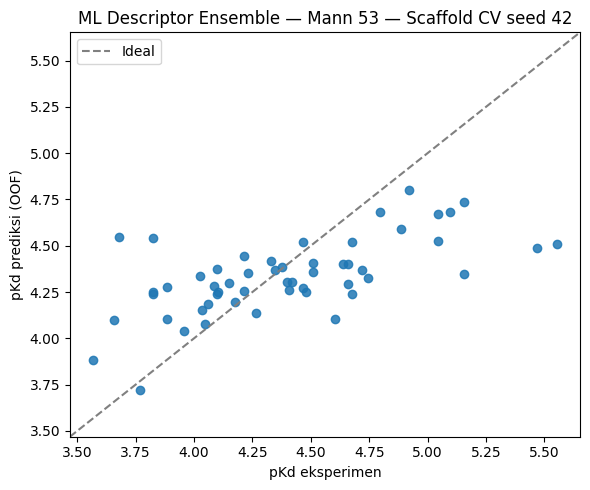

In [19]:
# Grafik prediksi silang out-of-fold, scaffold seed=42
p = preds.query("metode == 'scaffold' and seed == 42")
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(p['pKd_eksperimen'], p['pKd_prediksi'], alpha=.85)
lims = [min(p['pKd_eksperimen'].min(),p['pKd_prediksi'].min())-.1,
        max(p['pKd_eksperimen'].max(),p['pKd_prediksi'].max())+.1]
ax.plot(lims, lims, '--', color='gray', label='Ideal')
ax.set(xlabel='pKd eksperimen',ylabel='pKd prediksi (OOF)',
       title='ML Descriptor Ensemble — Mann 53 — Scaffold CV seed 42',xlim=lims,ylim=lims)
ax.legend(); fig.tight_layout()
fig.savefig(OUT/'ML_Ensemble_grafik_scaffold_seed42.png',dpi=200)
plt.show()

In [20]:
# Final fitting untuk prediksi senyawa baru; jangan laporkan skor training sebagai validasi.
final_model = make_model().fit(X, y)
joblib.dump({'model':final_model, 'descriptor_names':desc_names, 'n_descriptor':nD,
             'fingerprint_bits':1024, 'morgan_radius':2, 'member_names':MEMBER_NAMES,
             'training_SMILES':df['Smiles'].tolist(), 'training_pKd':y.tolist(),
             'catatan':'Model full-data. Validasi hanya dari OOF CV; dua assay belum dipisahkan.'},
            OUT/'ML_Ensemble_model_final.joblib')
print('Model final dilatih pada seluruh',len(y),'senyawa dan disimpan di:',OUT)

Model final dilatih pada seluruh 53 senyawa dan disimpan di: /workspace/USP5_MANN_53/ML_Ensemble


# Eksperimen ke-3 — Optimasi Terarah USP5 Mann 53

**Tiga tahap:** (1) 3 kandidat, (2) nested CV random & scaffold, (3) perbandingan baseline dan penyimpanan.

In [21]:
from pathlib import Path
import warnings, time, json
import numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
import joblib
warnings.filterwarnings('ignore', category=FutureWarning)
OUT = Path('/workspace/USP5_MANN_53/Optimasi_Terarah')
OUT.mkdir(parents=True, exist_ok=True)
URL = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv'
df = pd.read_csv(URL)
df.columns = df.columns.str.strip()
assert len(df)==53 and {'Smiles','pKd','Molecule ChEMBL ID'}.issubset(df.columns)
y = pd.to_numeric(df['pKd'],errors='raise').to_numpy(float)
mols = [Chem.MolFromSmiles(s) for s in df['Smiles']]
assert all(m is not None for m in mols) and np.isfinite(y).all()
groups = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
assert len(set(groups)) >= 5
fpgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN = np.asarray([fpgen.GetCountFingerprintAsNumPy(m) for m in mols],float)
MACCS = np.asarray([np.asarray(MACCSkeys.GenMACCSKeys(m),dtype=float) for m in mols])
X = np.hstack([MORGAN,MACCS])
print('Dataset:',len(y),'senyawa | scaffold unik:',len(set(groups)),'| fitur:',X.shape[1])
print('Rentang pKd:',round(y.min(),3),'-',round(y.max(),3),'| output:',OUT)


Dataset: 53 senyawa | scaffold unik: 25 | fitur: 1191
Rentang pKd: 3.569 - 5.553 | output: /workspace/USP5_MANN_53/Optimasi_Terarah


In [22]:
# TIGA keluarga algoritma, maksimal 3 konfigurasi per keluarga.
# Seluruh preprocessing dipelajari dari training fold, tidak dari validasi.
def linear_pipe(est):
    return Pipeline([('impute',SimpleImputer(strategy='median')),
                     ('var',VarianceThreshold()),('scale',StandardScaler()),('reg',est)])
def forest_pipe(est):
    return Pipeline([('impute',SimpleImputer(strategy='median')),
                     ('var',VarianceThreshold()),('reg',est)])
CANDIDATES = {
  'Ridge': [linear_pipe(Ridge(alpha=a)) for a in (1.,10.,100.)],
  'SVR_RBF': [linear_pipe(SVR(kernel='rbf',C=c,epsilon=0.10,gamma='scale')) for c in (.3,1.,3.)],
  'RandomForest': [forest_pipe(RandomForestRegressor(n_estimators=120,min_samples_leaf=leaf,
                            max_features=feat,random_state=42,n_jobs=1))
                   for leaf,feat in ((1,.5),(2,.5),(3,1.0))]
}
print('Model:', ', '.join(f'{k} ({len(v)} konfigurasi)' for k,v in CANDIDATES.items()))


Model: Ridge (3 konfigurasi), SVR_RBF (3 konfigurasi), RandomForest (3 konfigurasi)


In [23]:
def split_cv(kind, n_splits, seed, indices):
    if kind == 'random':
        return list(KFold(n_splits=n_splits,shuffle=True,random_state=seed).split(indices))
    g = groups[indices]
    if len(np.unique(g)) < n_splits:
        raise ValueError('Scaffold unik pada training kurang dari jumlah inner fold')
    return list(GroupKFold(n_splits=n_splits,shuffle=True,random_state=seed).split(indices,groups=g))

def inner_rmse(est, train_idx, kind, seed):
    vals=[]
    for a,b in split_cv(kind,3,seed,train_idx):
        tr,va=train_idx[a],train_idx[b]
        if kind=='scaffold': assert set(groups[tr]).isdisjoint(set(groups[va]))
        fitted=clone(est).fit(X[tr],y[tr])
        vals.append(np.sqrt(mean_squared_error(y[va],fitted.predict(X[va]))))
    return float(np.mean(vals))

def run_outer(kind,seed=42):
    t0=time.time(); outer=split_cv(kind,5,seed,np.arange(len(y)))
    pred=np.full(len(y),np.nan); fold_ids=np.zeros(len(y),int); choices=[]
    for fold,(tr,te) in enumerate(outer,1):
        if kind=='scaffold':assert set(groups[tr]).isdisjoint(set(groups[te]))
        trials=[]
        for name,configs in CANDIDATES.items():
            for idx,est in enumerate(configs):
                try:
                    rmse=inner_rmse(est,tr,kind,seed+fold)
                    trials.append((rmse,name,idx))
                except Exception as e:
                    print('Konfigurasi gagal:',name,idx,str(e)[:120])
        if not trials:raise RuntimeError('Tidak ada konfigurasi yang berhasil')
        best_rmse,name,idx=min(trials,key=lambda z:z[0])
        best=clone(CANDIDATES[name][idx]).fit(X[tr],y[tr])
        pred[te]=best.predict(X[te]);fold_ids[te]=fold
        choices.append({'metode':kind,'fold':fold,'model':name,'config_id':idx,
                        'inner_RMSE':best_rmse,'n_train':len(tr),'n_valid':len(te)})
        print(f'{kind:8s} fold {fold}/5: {name} (config {idx}), inner RMSE {best_rmse:.3f}')
    result={'metode':kind,'seed':seed,'R2':r2_score(y,pred),
            'RMSE':float(np.sqrt(mean_squared_error(y,pred))),
            'MAE':float(mean_absolute_error(y,pred))}
    print(f'>>> {kind}: R²={result["R2"]:.4f} | RMSE={result["RMSE"]:.4f} | MAE={result["MAE"]:.4f} | {time.time()-t0:.1f} detik')
    return result,pred,fold_ids,choices

results=[]; prediction_tables=[]; selected=[]
for kind in ('random','scaffold'):
    score,pred,foldids,choices=run_outer(kind)
    results.append(score);selected.extend(choices)
    prediction_tables.append(pd.DataFrame({'Molecule ChEMBL ID':df['Molecule ChEMBL ID'],
        'pKd_eksperimen':y,'pKd_prediksi_OOF':pred,'metode':kind,'fold':foldids}))


random   fold 1/5: Ridge (config 2), inner RMSE 0.301
random   fold 2/5: Ridge (config 2), inner RMSE 0.323
random   fold 3/5: RandomForest (config 0), inner RMSE 0.295
random   fold 4/5: Ridge (config 1), inner RMSE 0.285
random   fold 5/5: RandomForest (config 0), inner RMSE 0.372
>>> random: R²=0.3806 | RMSE=0.3625 | MAE=0.2590 | 8.7 detik
scaffold fold 1/5: Ridge (config 1), inner RMSE 0.406
scaffold fold 2/5: Ridge (config 0), inner RMSE 0.419
scaffold fold 3/5: RandomForest (config 0), inner RMSE 0.431
scaffold fold 4/5: Ridge (config 1), inner RMSE 0.265
scaffold fold 5/5: Ridge (config 0), inner RMSE 0.379
>>> scaffold: R²=0.1821 | RMSE=0.4165 | MAE=0.3283 | 9.2 detik


In [24]:
scores=pd.DataFrame(results)
# Baseline seed 42 dari notebook ML Ensemble, tercatat pada hasil eksperimen sebelumnya.
# Bandingkan sebagai indikasi, bukan bukti hasil tes independen.
baseline=pd.DataFrame([
    {'model':'ML Descriptor Ensemble (baseline)','metode':'random','R2':0.571,'RMSE':0.302,'MAE':0.225},
    {'model':'ML Descriptor Ensemble (baseline)','metode':'scaffold','R2':0.352,'RMSE':0.371,'MAE':0.282}
])
current=scores.copy();current.insert(0,'model','Optimasi terarah (nested CV)')
comparison=pd.concat([baseline,current],ignore_index=True)
print('=== PERBANDINGAN SEED 42 ===')
display(comparison.round(4))
print('=== MODEL TERPILIH PER FOLD ===')
display(pd.DataFrame(selected))
scores.to_csv(OUT/'optimasi_nestedCV_skor.csv',index=False)
pd.concat(prediction_tables,ignore_index=True).to_csv(OUT/'optimasi_prediksi_OOF.csv',index=False)
pd.DataFrame(selected).to_csv(OUT/'optimasi_model_terpilih.csv',index=False)
comparison.to_csv(OUT/'optimasi_vs_baseline.csv',index=False)
print('File hasil disimpan ke:',OUT)
print('CATATAN: baseline di atas dari seed 42, bukan rerun; protokol nested berbeda dari model baseline fixed.')
print('Metrik keduanya adalah estimasi CV, bukan external test.')


=== PERBANDINGAN SEED 42 ===


,model,metode,R2,RMSE,MAE,seed
0,ML Descriptor Ensemble (baseline),random,0.5710,0.3020,0.2250,NaN
1,ML Descriptor Ensemble (baseline),scaffold,0.3520,0.3710,0.2820,NaN
2,Optimasi terarah (nested CV),random,0.3806,0.3625,0.2590,42.0
3,Optimasi terarah (nested CV),scaffold,0.1821,0.4165,0.3283,42.0


=== MODEL TERPILIH PER FOLD ===


,metode,fold,model,config_id,inner_RMSE,n_train,n_valid
0,random,1,Ridge,2,0.301353,42,11
1,random,2,Ridge,2,0.322889,42,11
2,random,3,RandomForest,0,0.295172,42,11
3,random,4,Ridge,1,0.284992,43,10
4,random,5,RandomForest,0,0.372493,43,10
5,scaffold,1,Ridge,1,0.405871,48,5
6,scaffold,2,Ridge,0,0.419033,46,7
7,scaffold,3,RandomForest,0,0.431092,26,27
8,scaffold,4,Ridge,1,0.265116,46,7
9,scaffold,5,Ridge,0,0.379322,46,7


File hasil disimpan ke: /workspace/USP5_MANN_53/Optimasi_Terarah
CATATAN: baseline di atas dari seed 42, bukan rerun; protokol nested berbeda dari model baseline fixed.
Metrik keduanya adalah estimasi CV, bukan external test.


# USP5 — Latih di Data Lebih Banyak, Uji di 53 Senyawa Mann

**Apa tujuan notebook ini?** Hasil model dosen turun saat dipakai di 53 senyawa. Notebook ini mencoba tiga hal, dengan aturan yang adil:

1. **Memastikan** apakah 53 senyawa Mann benar-benar ada di dataset 80 (dicek lewat ChEMBL ID dan struktur).
2. **Skenario A vs B.** A: model dilatih hanya dengan senyawa Mann. B: model dilatih dengan semua senyawa (80), tetapi **diuji hanya pada senyawa Mann**. Senyawa uji dan pembagian foldnya sama persis di A dan B, jadi perbandingannya adil.
3. **Fitur lebih ringkas** (model Ridge dengan 15 deskriptor) dan **ukuran tambahan** (Spearman dan pembanding "tebak rata-rata").

In [1]:

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rdkit import Chem, rdBase
from rdkit.Chem import Descriptors, MACCSkeys, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.ML.Descriptors import MoleculeDescriptors
from sklearn.base import BaseEstimator, RegressorMixin, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import BayesianRidge, Ridge
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import KFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from scipy.stats import spearmanr

warnings.filterwarnings('ignore', category=FutureWarning)
OUT = Path('hasil_skenario_80_uji_53')
OUT.mkdir(parents=True, exist_ok=True)
print('RDKit:', rdBase.rdkitVersion, '| folder hasil:', OUT.resolve())

RDKit: 2026.09.1 | folder hasil: /data/Aliya/model /hasil_skenario_80_uji_53


In [2]:

URL_80 = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_pKd_80.csv'
URL_53 = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv'

df80 = pd.read_csv(URL_80)
df53 = pd.read_csv(URL_53)
for d in (df80, df53):
    d.columns = d.columns.str.strip()      # buang spasi liar di nama kolom

wajib = {'Molecule ChEMBL ID', 'Smiles', 'pKd'}
assert wajib.issubset(df80.columns), f'Kolom 80 kurang: {wajib - set(df80.columns)}'
assert wajib.issubset(df53.columns), f'Kolom 53 kurang: {wajib - set(df53.columns)}'
df80['pKd'] = pd.to_numeric(df80['pKd'], errors='raise')
df53['pKd'] = pd.to_numeric(df53['pKd'], errors='raise')
print('Jumlah baris  | dataset 80:', len(df80), '| dataset 53:', len(df53))

Jumlah baris  | dataset 80: 80 | dataset 53: 53


## Memastikan 53 Senyawa Itu Ada di Dataset 80

In [3]:
def kanonik(smiles):
    # Ubah SMILES ke bentuk baku supaya struktur yang sama selalu tertulis sama.
    m = Chem.MolFromSmiles(smiles)
    return Chem.MolToSmiles(m, canonical=True) if m is not None else None

df80['key'] = df80['Smiles'].apply(kanonik)
df53['key'] = df53['Smiles'].apply(kanonik)
assert df80['key'].notna().all() and df53['key'].notna().all(), 'Ada SMILES yang gagal dibaca'

id80, id53 = set(df80['Molecule ChEMBL ID']), set(df53['Molecule ChEMBL ID'])
key80, key53 = set(df80['key']), set(df53['key'])

print('=== Cek lewat ChEMBL ID ===')
print('ID 53 yang ada di 80   :', len(id53 & id80), 'dari', len(id53))
print('=== Cek lewat struktur ===')
print('Struktur 53 yang ada di 80:', len(key53 & key80), 'dari', len(key53))

hilang = df53[~df53['key'].isin(key80)]
if len(hilang) == 0:
    print('\nKESIMPULAN: semua 53 senyawa Mann ADA di dataset 80.')
else:
    print(f'\nKESIMPULAN: {len(hilang)} senyawa Mann TIDAK ada di dataset 80 (tetap dipakai, lihat tabel):')
    display(hilang[['Molecule ChEMBL ID', 'Smiles', 'pKd']])

# Bandingkan pKd untuk senyawa yang sama di dua file
gabung = df53.merge(df80[['key', 'pKd']], on='key', suffixes=('_53', '_80'))
gabung['selisih'] = (gabung['pKd_53'] - gabung['pKd_80']).abs()
print('\nSelisih pKd maksimum pada senyawa yang sama:', round(float(gabung['selisih'].max()), 4) if len(gabung) else 'tidak ada')
if len(gabung) and (gabung['selisih'] > 0.01).any():
    print('Ada senyawa dengan selisih pKd > 0.01, periksa:')
    display(gabung.loc[gabung['selisih'] > 0.01, ['Molecule ChEMBL ID', 'pKd_53', 'pKd_80', 'selisih']])

=== Cek lewat ChEMBL ID ===
ID 53 yang ada di 80   : 53 dari 53
=== Cek lewat struktur ===
Struktur 53 yang ada di 80: 53 dari 53

KESIMPULAN: semua 53 senyawa Mann ADA di dataset 80.

Selisih pKd maksimum pada senyawa yang sama: 0.0401
Ada senyawa dengan selisih pKd > 0.01, periksa:


,Molecule ChEMBL ID,pKd_53,pKd_80,selisih
11,CHEMBL5266862,5.468521,5.508638,0.040117


In [4]:

mann = df53[['Molecule ChEMBL ID', 'Smiles', 'pKd', 'key']].copy()
mann['is_mann53'] = True
tambahan = df80.loc[~df80['key'].isin(key53), ['Molecule ChEMBL ID', 'Smiles', 'pKd', 'key']].copy()
tambahan['is_mann53'] = False

df_all = pd.concat([mann, tambahan], ignore_index=True)
assert not df_all['key'].duplicated().any(), 'Masih ada struktur ganda di tabel gabungan'
print('Total senyawa gabungan :', len(df_all))
print('  - senyawa Mann (uji)  :', int(df_all['is_mann53'].sum()))
print('  - tambahan (latihan)  :', int((~df_all['is_mann53']).sum()))
print('Rentang pKd Mann       :', round(df_all.loc[df_all.is_mann53, 'pKd'].min(), 3), '-', round(df_all.loc[df_all.is_mann53, 'pKd'].max(), 3))
print('Rentang pKd tambahan   :', round(df_all.loc[~df_all.is_mann53, 'pKd'].min(), 3), '-', round(df_all.loc[~df_all.is_mann53, 'pKd'].max(), 3))
print('SD pKd Mann (pembanding RMSE tebak-rata-rata):', round(df_all.loc[df_all.is_mann53, 'pKd'].std(ddof=0), 3))

Total senyawa gabungan : 80
  - senyawa Mann (uji)  : 53
  - tambahan (latihan)  : 27
Rentang pKd Mann       : 3.569 - 5.553
Rentang pKd tambahan   : 3.032 - 5.347
SD pKd Mann (pembanding RMSE tebak-rata-rata): 0.461


In [5]:
mols = [Chem.MolFromSmiles(s) for s in df_all['Smiles']]
groups = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
y = df_all['pKd'].to_numpy(dtype=float)
is53 = df_all['is_mann53'].to_numpy(dtype=bool)

desc_names = [n for n, _ in Descriptors._descList]
calc = MoleculeDescriptors.MolecularDescriptorCalculator(desc_names)
DESC = np.asarray([calc.CalcDescriptors(m) for m in mols], dtype=float)
DESC[~np.isfinite(DESC)] = np.nan            # nilai tak hingga dianggap kosong; diisi nanti di dalam fold

mgen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=1024)
MORGAN = np.asarray([mgen.GetCountFingerprintAsNumPy(m) for m in mols], dtype=float)
MACCS = np.asarray([np.asarray(MACCSkeys.GenMACCSKeys(m), dtype=float) for m in mols])

X = np.hstack([DESC, MORGAN, MACCS])
nD, nM = DESC.shape[1], MORGAN.shape[1]
IDX_DESC = np.arange(0, nD)                  # kolom deskriptor saja
IDX_FPMA = np.arange(nD, X.shape[1])         # Morgan + MACCS
IDX_DESCFP = np.arange(0, nD + nM)           # deskriptor + Morgan

print('Bentuk fitur:', X.shape, '| scaffold unik (semua):', len(set(groups)),
      '| scaffold unik (Mann):', len(set(groups[is53])))

Bentuk fitur: (80, 1408) | scaffold unik (semua): 38 | scaffold unik (Mann): 25


In [6]:

class BlockSelector(BaseEstimator, TransformerMixin):
    # Mengambil hanya kolom tertentu dari tabel fitur.
    def __init__(self, idx): self.idx = idx
    def fit(self, X, y=None): return self
    def transform(self, X): return np.asarray(X)[:, self.idx]

class TopKCorr(BaseEstimator, TransformerMixin):
    # Memilih k kolom yang paling berkorelasi dengan pKd (hanya memakai data latih).
    def __init__(self, k=15): self.k = k
    def fit(self, X, y=None):
        Xc = X - X.mean(axis=0)
        yc = y - y.mean()
        denom = np.sqrt((Xc ** 2).sum(axis=0)) * np.sqrt((yc ** 2).sum())
        r = np.abs((Xc * yc[:, None]).sum(axis=0) / np.where(denom == 0, np.nan, denom))
        r = np.nan_to_num(r, nan=0.0)
        self.idx_ = np.argsort(-r)[:min(self.k, X.shape[1])]
        return self
    def transform(self, X): return X[:, self.idx_]

class MeanEnsemble(BaseEstimator, RegressorMixin):
    # Melatih beberapa model lalu merata-ratakan prediksinya.
    def __init__(self, members=None): self.members = members
    def fit(self, X, y):
        self.fitted_ = [clone(m).fit(X, y) for m in self.members]
        return self
    def predict(self, X):
        return np.column_stack([np.ravel(m.predict(X)) for m in self.fitted_]).mean(axis=1)

def pipe(idx, est, topk=None):
    # Urutan: pilih kolom -> isi nilai kosong -> buang kolom konstan -> samakan skala -> (pilih top-k) -> model
    steps = [('select', BlockSelector(idx)),
             ('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
             ('variance', VarianceThreshold(threshold=0.0)),
             ('scale', StandardScaler())]
    if topk is not None:
        steps.append(('topk', TopKCorr(k=topk)))
    steps.append(('estimator', est))
    return Pipeline(steps)

def model_ensemble_lama():
    return MeanEnsemble(members=[
        pipe(IDX_FPMA, BayesianRidge()),
        pipe(IDX_FPMA, SVR(kernel='linear', C=0.3, epsilon=0.05)),
        pipe(IDX_DESCFP, GradientBoostingRegressor(n_estimators=400, learning_rate=0.05,
                                                   max_depth=3, subsample=0.8, random_state=42)),
    ])

def model_ridge_ringkas():
    return MeanEnsemble(members=[pipe(IDX_DESC, Ridge(alpha=10.0), topk=15)])

def model_gabungan():
    return MeanEnsemble(members=[model_ensemble_lama(), model_ridge_ringkas()])

MODELS = {'Ensemble_lama': model_ensemble_lama,
          'Ridge_ringkas': model_ridge_ringkas,
          'Gabungan': model_gabungan}
print('Model siap:', ', '.join(MODELS))
     

Model siap: Ensemble_lama, Ridge_ringkas, Gabungan


## Aturan Ujian: Bagaimana Data Dibagi

**Apa ini?** Bagian terpenting supaya perbandingan A dan B adil.

- **Senyawa uji selalu senyawa Mann saja**, dibagi 5 fold. Pada protokol *scaffold*, satu scaffold hanya muncul di satu fold, jadi model diuji pada kerangka molekul yang belum pernah dilihat.
- **Skenario A**: model dilatih memakai senyawa Mann yang bukan fold uji.
- **Skenario B**: model dilatih memakai **semua** senyawa (Mann + tambahan) yang bukan fold uji.
- Untuk protokol scaffold, senyawa latih yang scaffold-nya sama dengan senyawa uji **dibuang dari data latih**. Ini mencegah kebocoran data (*data leakage*).
- Sebagai pembanding, dihitung juga **"tebak rata-rata"**: kalau model hanya menebak rata-rata pKd latih, berapa RMSE-nya? Model yang bagus harus lebih baik dari itu.

In [7]:
idx53 = np.where(is53)[0]

def scaffold_fold_ids(idx, seed, n_folds=5):
    # Bagi senyawa per scaffold, dibuat seimbang ukurannya, urutan scaffold diacak per seed.
    rng = np.random.RandomState(seed)
    g = groups[idx]
    unik = np.unique(g)
    rng.shuffle(unik)
    ukuran = {u: int((g == u).sum()) for u in unik}
    urut = sorted(unik, key=lambda u: -ukuran[u])
    beban = np.zeros(n_folds)
    tugas = {}
    for u in urut:
        f = int(np.argmin(beban))
        tugas[u] = f
        beban[f] += ukuran[u]
    return np.array([tugas[x] for x in g])

def buat_fold_uji(kind, seed):
    if kind == 'scaffold':
        fid = scaffold_fold_ids(idx53, seed)
        return [idx53[fid == k] for k in range(5) if (fid == k).any()]
    return [idx53[te] for _, te in KFold(5, shuffle=True, random_state=seed).split(idx53)]

def indeks_latih(skenario, uji, kind):
    pool = idx53 if skenario == 'A_latih_Mann_saja' else np.arange(len(y))
    pool = np.setdiff1d(pool, uji)
    if kind == 'scaffold':
        pool = pool[~np.isin(groups[pool], np.unique(groups[uji]))]
    return pool

def evaluasi(model_fn, skenario, kind, seed):
    pos = {int(i): p for p, i in enumerate(idx53)}
    pred = np.full(len(idx53), np.nan)
    tebak = np.full(len(idx53), np.nan)
    n_latih = []
    for uji in buat_fold_uji(kind, seed):
        latih = indeks_latih(skenario, uji, kind)
        assert set(latih).isdisjoint(set(uji)), 'Data uji bocor ke data latih'
        if kind == 'scaffold':
            assert set(groups[latih]).isdisjoint(set(groups[uji])), 'Scaffold bocor'
        model = model_fn().fit(X[latih], y[latih])
        p = model.predict(X[uji])
        for i, v in zip(uji, p):
            pred[pos[int(i)]] = v
            tebak[pos[int(i)]] = y[latih].mean()
        n_latih.append(len(latih))
    assert np.isfinite(pred).all()
    yt = y[idx53]
    hasil = dict(R2=r2_score(yt, pred),
                 RMSE=float(np.sqrt(mean_squared_error(yt, pred))),
                 MAE=mean_absolute_error(yt, pred),
                 Spearman=float(spearmanr(yt, pred).correlation),
                 RMSE_tebak_rata2=float(np.sqrt(mean_squared_error(yt, tebak))),
                 rata2_n_latih=float(np.mean(n_latih)))
    return hasil, pred

print('Senyawa uji (Mann):', len(idx53), '| aturan ujian siap')
     

Senyawa uji (Mann): 53 | aturan ujian siap


In [8]:
SEEDS = [42, 123, 2026, 7, 99]
SKENARIO = ['A_latih_Mann_saja', 'B_latih_semua_uji_Mann']

baris, oof = [], {}
for kind in ['scaffold', 'random']:
    for sk in SKENARIO:
        for nama, fn in MODELS.items():
            for seed in SEEDS:
                hasil, pred = evaluasi(fn, sk, kind, seed)
                baris.append(dict(protokol=kind, skenario=sk, model=nama, seed=seed, **hasil))
                oof[(kind, sk, nama, seed)] = pred
            print(f'selesai: {kind:8s} | {sk:24s} | {nama}')

hasil_seed = pd.DataFrame(baris)
hasil_seed.to_csv(OUT / 'hasil_per_seed.csv', index=False)
print('\nTersimpan:', OUT / 'hasil_per_seed.csv')

selesai: scaffold | A_latih_Mann_saja        | Ensemble_lama
selesai: scaffold | A_latih_Mann_saja        | Ridge_ringkas
selesai: scaffold | A_latih_Mann_saja        | Gabungan
selesai: scaffold | B_latih_semua_uji_Mann   | Ensemble_lama
selesai: scaffold | B_latih_semua_uji_Mann   | Ridge_ringkas
selesai: scaffold | B_latih_semua_uji_Mann   | Gabungan
selesai: random   | A_latih_Mann_saja        | Ensemble_lama
selesai: random   | A_latih_Mann_saja        | Ridge_ringkas
selesai: random   | A_latih_Mann_saja        | Gabungan
selesai: random   | B_latih_semua_uji_Mann   | Ensemble_lama
selesai: random   | B_latih_semua_uji_Mann   | Ridge_ringkas
selesai: random   | B_latih_semua_uji_Mann   | Gabungan

Tersimpan: hasil_skenario_80_uji_53/hasil_per_seed.csv


In [9]:
ringkas = (hasil_seed
           .groupby(['protokol', 'skenario', 'model'])[['R2', 'RMSE', 'Spearman', 'RMSE_tebak_rata2', 'rata2_n_latih']]
           .agg(['mean', 'std']).round(3))
ringkas.to_csv(OUT / 'ringkasan.csv')

print('=== PROTOKOL SCAFFOLD (paling relevan: senyawa dengan kerangka baru) ===')
display(ringkas.loc['scaffold'])
print('=== PROTOKOL ACAK (referensi) ===')
display(ringkas.loc['random'])

=== PROTOKOL SCAFFOLD (paling relevan: senyawa dengan kerangka baru) ===


R2          RMSE        Spearman  \
                                       mean    std   mean    std     mean   
skenario               model                                                
A_latih_Mann_saja      Ensemble_lama  0.362  0.022  0.368  0.006    0.650   
                       Gabungan       0.151  0.045  0.424  0.011    0.414   
                       Ridge_ringkas -0.197  0.107  0.503  0.023    0.184   
B_latih_semua_uji_Mann Ensemble_lama  0.386  0.021  0.361  0.006    0.673   
                       Gabungan       0.214  0.014  0.408  0.004    0.581   
                       Ridge_ringkas -0.087  0.025  0.480  0.005    0.093   

                                            RMSE_tebak_rata2         \
                                        std             mean    std   
skenario               model                                          
A_latih_Mann_saja      Ensemble_lama  0.021            0.481  0.004   
                       Gabungan       0.069            0.481  0.004   
                       Ridge_ringkas  0.088            0.481  0.004   
B_latih_semua_uji_Mann Ensemble_lama  0.016            0.596  0.003   
                       Gabungan       0.017            0.596  0.003   
                       Ridge_ringkas  0.045            0.596  0.003   

                                     rata2_n_latih       
                                              mean  std  
skenario               model                             
A_latih_Mann_saja      Ensemble_lama          42.4  0.0  
                       Gabungan               42.4  0.0  
                       Ridge_ringkas          42.4  0.0  
B_latih_semua_uji_Mann Ensemble_lama          68.6  0.0  
                       Gabungan               68.6  0.0  
                       Ridge_ringkas          68.6  0.0

=== PROTOKOL ACAK (referensi) ===


R2          RMSE        Spearman  \
                                       mean    std   mean    std     mean   
skenario               model                                                
A_latih_Mann_saja      Ensemble_lama  0.585  0.014  0.297  0.005    0.741   
                       Gabungan       0.499  0.045  0.326  0.015    0.678   
                       Ridge_ringkas  0.252  0.171  0.396  0.043    0.511   
B_latih_semua_uji_Mann Ensemble_lama  0.584  0.018  0.297  0.006    0.767   
                       Gabungan       0.387  0.020  0.361  0.006    0.671   
                       Ridge_ringkas -0.063  0.034  0.475  0.008    0.124   

                                            RMSE_tebak_rata2         \
                                        std             mean    std   
skenario               model                                          
A_latih_Mann_saja      Ensemble_lama  0.017            0.473  0.004   
                       Gabungan       0.044            0.473  0.004   
                       Ridge_ringkas  0.064            0.473  0.004   
B_latih_semua_uji_Mann Ensemble_lama  0.015            0.563  0.002   
                       Gabungan       0.031            0.563  0.002   
                       Ridge_ringkas  0.064            0.563  0.002   

                                     rata2_n_latih       
                                              mean  std  
skenario               model                             
A_latih_Mann_saja      Ensemble_lama          42.4  0.0  
                       Gabungan               42.4  0.0  
                       Ridge_ringkas          42.4  0.0  
B_latih_semua_uji_Mann Ensemble_lama          69.4  0.0  
                       Gabungan               69.4  0.0  
                       Ridge_ringkas          69.4  0.0

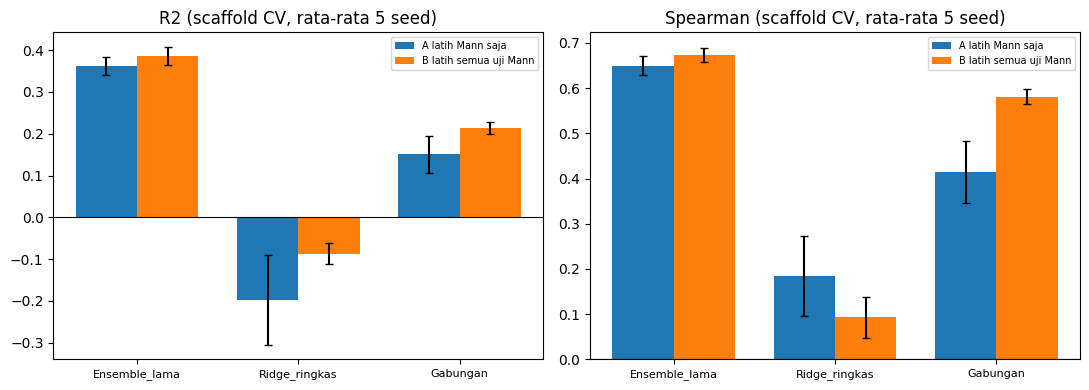

In [10]:

sc = hasil_seed[hasil_seed.protokol == 'scaffold']
agg = sc.groupby(['model', 'skenario'])[['R2', 'Spearman']].agg(['mean', 'std'])
nama_model = list(MODELS)
lebar = 0.38
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, metrik in zip(ax, ['R2', 'Spearman']):
    for j, sk in enumerate(SKENARIO):
        m = [agg.loc[(n, sk), (metrik, 'mean')] for n in nama_model]
        s = [agg.loc[(n, sk), (metrik, 'std')] for n in nama_model]
        a.bar(np.arange(len(nama_model)) + (j - 0.5) * lebar, m, lebar, yerr=s, capsize=3,
              label=sk.replace('_', ' '))
    a.axhline(0, color='k', lw=0.8)
    a.set_xticks(np.arange(len(nama_model)))
    a.set_xticklabels(nama_model, fontsize=8)
    a.set_title(f'{metrik} (scaffold CV, rata-rata 5 seed)')
    a.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT / 'grafik_perbandingan_scaffold.png', dpi=200, bbox_inches='tight')
plt.show()

# USP5 — Uji Per-Anggota Ensemble dan Uji Label Diacak

In [11]:

perlu = ['X', 'y', 'groups', 'is53', 'idx53', 'IDX_FPMA', 'IDX_DESCFP', 'pipe',
         'buat_fold_uji', 'indeks_latih', 'SEEDS', 'SKENARIO', 'OUT', 'hasil_seed',
         'r2_score', 'mean_squared_error', 'mean_absolute_error', 'spearmanr']
hilang = [n for n in perlu if n not in globals()]
assert not hilang, f'Jalankan dulu semua sel notebook sebelumnya. Yang hilang: {hilang}'
print('Prasyarat lengkap. Senyawa uji:', len(idx53), '| seed:', SEEDS)

Prasyarat lengkap. Senyawa uji: 53 | seed: [42, 123, 2026, 7, 99]


In [12]:

from sklearn.linear_model import BayesianRidge
from sklearn.svm import SVR
from sklearn.ensemble import GradientBoostingRegressor

def buat_anggota():
    # Sama persis dengan model_ensemble_lama() di notebook sebelumnya.
    return {
        'BayesianRidge':    pipe(IDX_FPMA,   BayesianRidge()),
        'SVR_linear':       pipe(IDX_FPMA,   SVR(kernel='linear', C=0.3, epsilon=0.05)),
        'GradientBoosting': pipe(IDX_DESCFP, GradientBoostingRegressor(n_estimators=400, learning_rate=0.05,
                                                                       max_depth=3, subsample=0.8, random_state=42)),
    }

NAMA_ANGGOTA = list(buat_anggota())
KOMBINASI = {
    'BR saja':            ['BayesianRidge'],
    'SVR saja':           ['SVR_linear'],
    'GB saja':            ['GradientBoosting'],
    'tanpa BR (SVR+GB)':  ['SVR_linear', 'GradientBoosting'],
    'tanpa SVR (BR+GB)':  ['BayesianRidge', 'GradientBoosting'],
    'tanpa GB (BR+SVR)':  ['BayesianRidge', 'SVR_linear'],
    'Ensemble penuh (3)': ['BayesianRidge', 'SVR_linear', 'GradientBoosting'],
}
print('Anggota  :', NAMA_ANGGOTA)
print('Kombinasi:', list(KOMBINASI))

Anggota  : ['BayesianRidge', 'SVR_linear', 'GradientBoosting']
Kombinasi: ['BR saja', 'SVR saja', 'GB saja', 'tanpa BR (SVR+GB)', 'tanpa SVR (BR+GB)', 'tanpa GB (BR+SVR)', 'Ensemble penuh (3)']


In [13]:
def evaluasi_anggota(skenario, kind, seed):
    pos = {int(i): p for p, i in enumerate(idx53)}
    pred_ang = {n: np.full(len(idx53), np.nan) for n in NAMA_ANGGOTA}
    tebak = np.full(len(idx53), np.nan)
    for uji in buat_fold_uji(kind, seed):
        latih = indeks_latih(skenario, uji, kind)
        assert set(latih).isdisjoint(set(uji)), 'Data uji bocor ke data latih'
        if kind == 'scaffold':
            assert set(groups[latih]).isdisjoint(set(groups[uji])), 'Scaffold bocor'
        p_uji = [pos[int(i)] for i in uji]
        for nama, est in buat_anggota().items():
            est.fit(X[latih], y[latih])
            pred_ang[nama][p_uji] = np.ravel(est.predict(X[uji]))
        tebak[p_uji] = y[latih].mean()
    yt = y[idx53]
    hasil = {}
    for kombi, daftar in KOMBINASI.items():
        p = np.mean([pred_ang[n] for n in daftar], axis=0)
        hasil[kombi] = dict(R2=r2_score(yt, p),
                            RMSE=float(np.sqrt(mean_squared_error(yt, p))),
                            MAE=mean_absolute_error(yt, p),
                            Spearman=float(spearmanr(yt, p).correlation))
    rmse_tebak = float(np.sqrt(mean_squared_error(yt, tebak)))
    return hasil, pred_ang, rmse_tebak

print('Fungsi siap')

Fungsi siap


In [14]:
PROTOKOL = ['scaffold', 'random']
baris, simpan_pred = [], {}
for kind in PROTOKOL:
    for sk in SKENARIO:
        for seed in SEEDS:
            hasil, pred_ang, rm_tebak = evaluasi_anggota(sk, kind, seed)
            simpan_pred[(kind, sk, seed)] = pred_ang
            for kombi, m in hasil.items():
                baris.append(dict(protokol=kind, skenario=sk, kombinasi=kombi, seed=seed,
                                  RMSE_tebak_rata2=rm_tebak, **m))
        print(f'selesai: {kind:8s} | {sk}')

hasil_ang = pd.DataFrame(baris)
hasil_ang.to_csv(OUT / 'hasil_anggota_per_seed.csv', index=False)
print('Tersimpan:', OUT / 'hasil_anggota_per_seed.csv')
     

selesai: scaffold | A_latih_Mann_saja
selesai: scaffold | B_latih_semua_uji_Mann
selesai: random   | A_latih_Mann_saja
selesai: random   | B_latih_semua_uji_Mann
Tersimpan: hasil_skenario_80_uji_53/hasil_anggota_per_seed.csv


In [15]:
lama = hasil_seed[hasil_seed['model'] == 'Ensemble_lama'][['protokol', 'skenario', 'seed', 'R2']]
baru = hasil_ang[hasil_ang['kombinasi'] == 'Ensemble penuh (3)'][['protokol', 'skenario', 'seed', 'R2']]
cek = lama.merge(baru, on=['protokol', 'skenario', 'seed'], suffixes=('_sebelumnya', '_sekarang'))
selisih = (cek['R2_sebelumnya'] - cek['R2_sekarang']).abs().max()
print('Baris yang dibandingkan :', len(cek))
print('Selisih R2 maksimum     :', f'{selisih:.2e}')
print('HASIL:', 'COCOK dengan hasil sebelumnya' if selisih < 1e-6 else 'ada selisih; periksa versi library atau seed')
     

Baris yang dibandingkan : 20
Selisih R2 maksimum     : 0.00e+00
HASIL: COCOK dengan hasil sebelumnya


In [16]:
urut = pd.CategoricalDtype(list(KOMBINASI), ordered=True)
hasil_ang['kombinasi'] = hasil_ang['kombinasi'].astype(urut)
ring = (hasil_ang.groupby(['protokol', 'skenario', 'kombinasi'], observed=True)[['R2', 'RMSE', 'Spearman']]
        .agg(['mean', 'std']).round(3))
ring.to_csv(OUT / 'ringkasan_anggota.csv')

print('=== PROTOKOL SCAFFOLD (utama) ===')
display(ring.loc['scaffold'])
print('=== PROTOKOL ACAK (referensi) ===')
display(ring.loc['random'])
     

=== PROTOKOL SCAFFOLD (utama) ===


R2          RMSE         \
                                            mean    std   mean    std   
skenario               kombinasi                                        
A_latih_Mann_saja      BR saja             0.411  0.024  0.353  0.007   
                       SVR saja            0.412  0.028  0.353  0.009   
                       GB saja             0.135  0.030  0.428  0.007   
                       tanpa BR (SVR+GB)   0.322  0.022  0.379  0.006   
                       tanpa SVR (BR+GB)   0.319  0.021  0.380  0.006   
                       tanpa GB (BR+SVR)   0.412  0.026  0.353  0.008   
                       Ensemble penuh (3)  0.362  0.022  0.368  0.006   
B_latih_semua_uji_Mann BR saja             0.414  0.017  0.353  0.005   
                       SVR saja            0.420  0.021  0.351  0.006   
                       GB saja             0.181  0.039  0.417  0.010   
                       tanpa BR (SVR+GB)   0.353  0.024  0.370  0.007   
                       tanpa SVR (BR+GB)   0.351  0.023  0.371  0.006   
                       tanpa GB (BR+SVR)   0.419  0.018  0.351  0.006   
                       Ensemble penuh (3)  0.386  0.021  0.361  0.006   

                                          Spearman         
                                              mean    std  
skenario               kombinasi                           
A_latih_Mann_saja      BR saja               0.667  0.025  
                       SVR saja              0.663  0.025  
                       GB saja               0.419  0.034  
                       tanpa BR (SVR+GB)     0.610  0.025  
                       tanpa SVR (BR+GB)     0.606  0.025  
                       tanpa GB (BR+SVR)     0.670  0.025  
                       Ensemble penuh (3)    0.650  0.021  
B_latih_semua_uji_Mann BR saja               0.662  0.014  
                       SVR saja              0.661  0.018  
                       GB saja               0.520  0.037  
                       tanpa BR (SVR+GB)     0.656  0.023  
                       tanpa SVR (BR+GB)     0.657  0.018  
                       tanpa GB (BR+SVR)     0.665  0.014  
                       Ensemble penuh (3)    0.673  0.016

=== PROTOKOL ACAK (referensi) ===


R2          RMSE         \
                                            mean    std   mean    std   
skenario               kombinasi                                        
A_latih_Mann_saja      BR saja             0.589  0.007  0.295  0.003   
                       SVR saja            0.569  0.008  0.302  0.003   
                       GB saja             0.447  0.059  0.342  0.018   
                       tanpa BR (SVR+GB)   0.566  0.025  0.303  0.009   
                       tanpa SVR (BR+GB)   0.569  0.021  0.302  0.007   
                       tanpa GB (BR+SVR)   0.582  0.007  0.298  0.002   
                       Ensemble penuh (3)  0.585  0.014  0.297  0.005   
B_latih_semua_uji_Mann BR saja             0.574  0.013  0.301  0.004   
                       SVR saja            0.572  0.008  0.301  0.003   
                       GB saja             0.454  0.038  0.340  0.012   
                       tanpa BR (SVR+GB)   0.571  0.022  0.302  0.008   
                       tanpa SVR (BR+GB)   0.564  0.024  0.304  0.008   
                       tanpa GB (BR+SVR)   0.579  0.008  0.299  0.003   
                       Ensemble penuh (3)  0.584  0.018  0.297  0.006   

                                          Spearman         
                                              mean    std  
skenario               kombinasi                           
A_latih_Mann_saja      BR saja               0.739  0.009  
                       SVR saja              0.729  0.012  
                       GB saja               0.655  0.052  
                       tanpa BR (SVR+GB)     0.732  0.018  
                       tanpa SVR (BR+GB)     0.733  0.019  
                       tanpa GB (BR+SVR)     0.735  0.011  
                       Ensemble penuh (3)    0.741  0.017  
B_latih_semua_uji_Mann BR saja               0.745  0.009  
                       SVR saja              0.741  0.013  
                       GB saja               0.707  0.034  
                       tanpa BR (SVR+GB)     0.758  0.025  
                       tanpa SVR (BR+GB)     0.755  0.022  
                       tanpa GB (BR+SVR)     0.746  0.010  
                       Ensemble penuh (3)    0.767  0.015

In [17]:
sk0, seed0 = SKENARIO[0], SEEDS[0]
pa = simpan_pred[('scaffold', sk0, seed0)]
resid = pd.DataFrame({n: y[idx53] - pa[n] for n in NAMA_ANGGOTA})
print(f'Korelasi residual antar anggota (scaffold, {sk0}, seed {seed0}):')
display(resid.corr().round(3))

Korelasi residual antar anggota (scaffold, A_latih_Mann_saja, seed 42):


,BayesianRidge,SVR_linear,GradientBoosting
BayesianRidge,1.000,0.997,0.899
SVR_linear,0.997,1.000,0.897
GradientBoosting,0.899,0.897,1.000


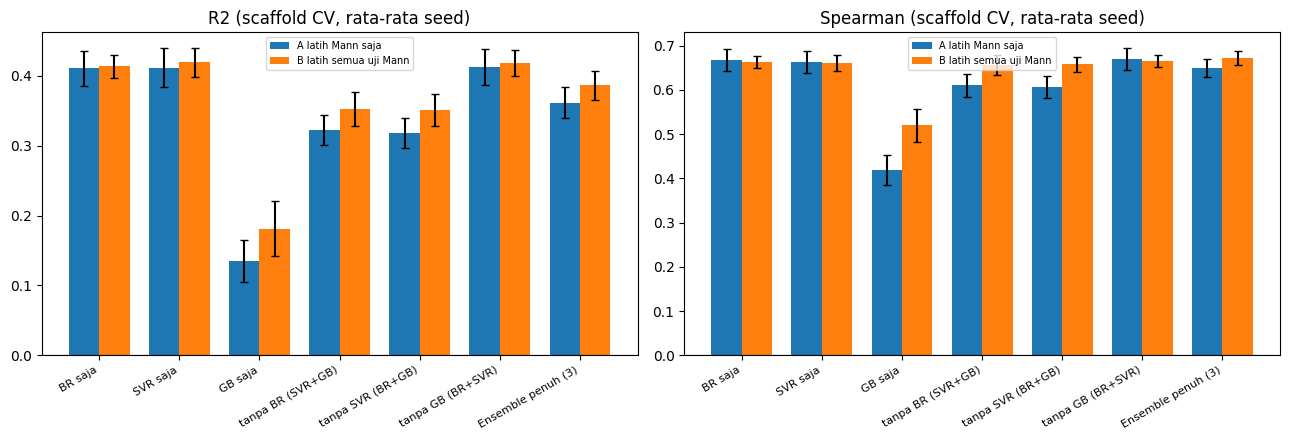

In [18]:
sc = hasil_ang[hasil_ang['protokol'] == 'scaffold']
agg = sc.groupby(['kombinasi', 'skenario'], observed=True)[['R2', 'Spearman']].agg(['mean', 'std'])
nama_k = list(KOMBINASI)
lebar = 0.38
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, metrik in zip(ax, ['R2', 'Spearman']):
    for j, sk in enumerate(SKENARIO):
        m = [agg.loc[(k, sk), (metrik, 'mean')] for k in nama_k]
        s = [agg.loc[(k, sk), (metrik, 'std')] for k in nama_k]
        a.bar(np.arange(len(nama_k)) + (j - 0.5) * lebar, m, lebar, yerr=s, capsize=3, label=sk.replace('_', ' '))
    a.axhline(0, color='k', lw=0.8)
    a.set_xticks(np.arange(len(nama_k)))
    a.set_xticklabels(nama_k, rotation=30, ha='right', fontsize=8)
    a.set_title(f'{metrik} (scaffold CV, rata-rata seed)')
    a.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT / 'grafik_anggota_scaffold.png', dpi=200, bbox_inches='tight')
plt.show()

R2 label asli   : 0.338
R2 label acak   : rata-rata -0.351 | maks -0.057 | min -0.887
Nilai p empiris : 0.048  (terkecil yang mungkin dengan 20 pengacakan = 0.048)
KESIMPULAN: model berada di atas semua hasil label acak (sinyal terdeteksi)


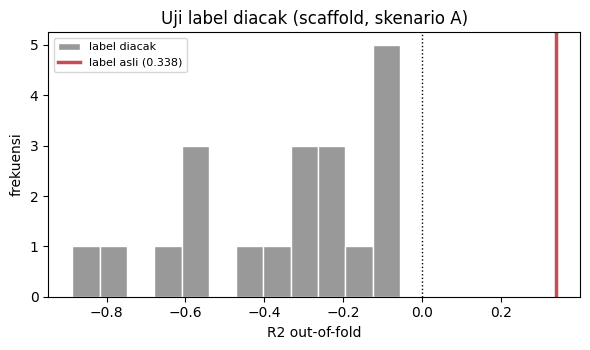

In [19]:

N_PERM = 20
kind_y, sk_y, seed_y = 'scaffold', SKENARIO[0], SEEDS[0]

# R2 asli untuk pembanding (dari hasil yang sama persis)
r2_asli = float(hasil_ang[(hasil_ang.protokol == kind_y) & (hasil_ang.skenario == sk_y) &
                          (hasil_ang.seed == seed_y) & (hasil_ang.kombinasi == 'Ensemble penuh (3)')]['R2'].iloc[0])

y_asli = y.copy()
rng = np.random.RandomState(0)
r2_acak = []
try:
    for i in range(N_PERM):
        y[:] = y_asli[rng.permutation(len(y_asli))]      # kocok jawaban (in-place)
        h, _, _ = evaluasi_anggota(sk_y, kind_y, seed_y)
        r2_acak.append(h['Ensemble penuh (3)']['R2'])
finally:
    y[:] = y_asli                                         # kembalikan y asli, apa pun yang terjadi
assert np.allclose(y, y_asli), 'y asli gagal dikembalikan!'

r2_acak = np.array(r2_acak)
p_empiris = (1 + (r2_acak >= r2_asli).sum()) / (1 + N_PERM)
print(f'R2 label asli   : {r2_asli:.3f}')
print(f'R2 label acak   : rata-rata {r2_acak.mean():.3f} | maks {r2_acak.max():.3f} | min {r2_acak.min():.3f}')
print(f'Nilai p empiris : {p_empiris:.3f}  (terkecil yang mungkin dengan {N_PERM} pengacakan = {1/(1+N_PERM):.3f})')
print('KESIMPULAN:', 'model berada di atas semua hasil label acak (sinyal terdeteksi)' if r2_asli > r2_acak.max()
      else 'model TIDAK jelas di atas label acak, hati-hati menafsirkan hasil')

plt.figure(figsize=(6, 3.6))
plt.hist(r2_acak, bins=12, color='#999999', edgecolor='white', label='label diacak')
plt.axvline(r2_asli, color='#C44E52', lw=2.5, label=f'label asli ({r2_asli:.3f})')
plt.axvline(0, color='k', lw=1, ls=':')
plt.xlabel('R2 out-of-fold'); plt.ylabel('frekuensi'); plt.title('Uji label diacak (scaffold, skenario A)')
plt.legend(fontsize=8); plt.tight_layout()
plt.savefig(OUT / 'grafik_y_randomization.png', dpi=200, bbox_inches='tight')
plt.show()
     

# USP5 — Uji Label Diacak 100 Kali untuk Model Linear

Ujian ini dilakukan untuk dua anggota linear yang terbukti paling bagus (**BayesianRidge** dan **SVR linear**), dan untuk dua skenario (A: latih Mann saja, B: latih semua). Dua ukuran dicek: **R²** dan **Spearman** (ketepatan urutan, yang paling penting untuk memilih kandidat).

GradientBoosting sengaja tidak diikutkan karena lambat dan sudah terbukti lemah. Ensemble penuh sudah diuji di sel sebelumnya (20 pengacakan).

In [20]:

perlu = ['X', 'y', 'groups', 'idx53', 'buat_anggota', 'buat_fold_uji', 'indeks_latih',
         'SEEDS', 'SKENARIO', 'OUT', 'r2_score', 'spearmanr', 'np', 'pd', 'plt']
hilang = [n for n in perlu if n not in globals()]
assert not hilang, f'Jalankan dulu notebook sebelumnya. Yang hilang: {hilang}'
print('Prasyarat lengkap | senyawa uji:', len(idx53), '| skenario:', SKENARIO)

Prasyarat lengkap | senyawa uji: 53 | skenario: ['A_latih_Mann_saja', 'B_latih_semua_uji_Mann']


In [21]:

def skor_anggota(nama, skenario, kind, seed):
    pos = {int(i): p for p, i in enumerate(idx53)}
    pred = np.full(len(idx53), np.nan)
    for uji in buat_fold_uji(kind, seed):
        latih = indeks_latih(skenario, uji, kind)
        assert set(latih).isdisjoint(set(uji)), 'Data uji bocor ke data latih'
        if kind == 'scaffold':
            assert set(groups[latih]).isdisjoint(set(groups[uji])), 'Scaffold bocor'
        est = buat_anggota()[nama]
        est.fit(X[latih], y[latih])
        for i, v in zip(uji, np.ravel(est.predict(X[uji]))):
            pred[pos[int(i)]] = v
    yt = y[idx53]
    rho = spearmanr(yt, pred).correlation
    return float(r2_score(yt, pred)), float(np.nan_to_num(rho))

KANDIDAT = ['BayesianRidge', 'SVR_linear']
SEED_Y = SEEDS[0]
print('Anggota diuji:', KANDIDAT, '| seed pembagian data:', SEED_Y)

Anggota diuji: ['BayesianRidge', 'SVR_linear'] | seed pembagian data: 42


In [22]:

asli = {}
for sk in SKENARIO:
    for nama in KANDIDAT:
        asli[(nama, sk)] = skor_anggota(nama, sk, 'scaffold', SEED_Y)
        print(f'{nama:14s} | {sk:24s} | R2 asli = {asli[(nama, sk)][0]:.3f} | Spearman asli = {asli[(nama, sk)][1]:.3f}')
     

BayesianRidge  | A_latih_Mann_saja        | R2 asli = 0.392 | Spearman asli = 0.674
SVR_linear     | A_latih_Mann_saja        | R2 asli = 0.384 | Spearman asli = 0.652
BayesianRidge  | B_latih_semua_uji_Mann   | R2 asli = 0.393 | Spearman asli = 0.644
SVR_linear     | B_latih_semua_uji_Mann   | R2 asli = 0.390 | Spearman asli = 0.640


In [23]:
N_PERM = 100
rng = np.random.RandomState(2026)
y_asli = y.copy()
acak = {(n, s): [] for n in KANDIDAT for s in SKENARIO}

try:
    for i in range(N_PERM):
        y[:] = y_asli[rng.permutation(len(y_asli))]          # kocok jawaban (in-place)
        for sk in SKENARIO:
            for nama in KANDIDAT:
                acak[(nama, sk)].append(skor_anggota(nama, sk, 'scaffold', SEED_Y))
        if (i + 1) % 20 == 0:
            print(f'pengacakan {i + 1}/{N_PERM} selesai')
finally:
    y[:] = y_asli                                             # kembalikan y asli, apa pun yang terjadi
assert np.allclose(y, y_asli), 'y asli gagal dikembalikan!'
print('y asli sudah dikembalikan dan dicek.')

pengacakan 20/100 selesai
pengacakan 40/100 selesai
pengacakan 60/100 selesai
pengacakan 80/100 selesai
pengacakan 100/100 selesai
y asli sudah dikembalikan dan dicek.


In [24]:
baris = []
for (nama, sk), daftar in acak.items():
    arr = np.array(daftar)                    # kolom 0 = R2, kolom 1 = Spearman
    for k, metrik in enumerate(['R2', 'Spearman']):
        nilai_asli = asli[(nama, sk)][k]
        p_emp = (1 + (arr[:, k] >= nilai_asli).sum()) / (1 + len(arr))
        baris.append(dict(anggota=nama, skenario=sk, metrik=metrik, asli=round(nilai_asli, 3),
                          acak_rata2=round(arr[:, k].mean(), 3), acak_maks=round(arr[:, k].max(), 3),
                          acak_min=round(arr[:, k].min(), 3), p_empiris=round(p_emp, 4),
                          kesimpulan='di atas semua label acak' if nilai_asli > arr[:, k].max()
                                     else 'TIDAK jelas di atas label acak'))
tabel_p = pd.DataFrame(baris)
tabel_p.to_csv(OUT / 'y_randomization_100.csv', index=False)

nilai_acak = pd.DataFrame([dict(anggota=n, skenario=s, pengacakan=i + 1, R2=r, Spearman=rho)
                           for (n, s), d in acak.items() for i, (r, rho) in enumerate(d)])
nilai_acak.to_csv(OUT / 'y_randomization_100_nilai_acak.csv', index=False)

print(f'Nilai p terkecil yang mungkin dengan {N_PERM} pengacakan: {1 / (1 + N_PERM):.4f}\n')
display(tabel_p)

Nilai p terkecil yang mungkin dengan 100 pengacakan: 0.0099



,anggota,skenario,metrik,asli,acak_rata2,acak_maks,acak_min,p_empiris,kesimpulan
0,BayesianRidge,A_latih_Mann_saja,R2,0.392,-0.411,0.035,-1.567,0.0099,di atas semua label acak
1,BayesianRidge,A_latih_Mann_saja,Spearman,0.674,-0.096,0.300,-0.476,0.0099,di atas semua label acak
2,BayesianRidge,B_latih_semua_uji_Mann,R2,0.393,-0.433,0.108,-1.426,0.0099,di atas semua label acak
3,BayesianRidge,B_latih_semua_uji_Mann,Spearman,0.644,-0.069,0.272,-0.447,0.0099,di atas semua label acak
4,SVR_linear,A_latih_Mann_saja,R2,0.384,-0.581,0.007,-2.199,0.0099,di atas semua label acak
5,SVR_linear,A_latih_Mann_saja,Spearman,0.652,-0.031,0.309,-0.346,0.0099,di atas semua label acak
6,SVR_linear,B_latih_semua_uji_Mann,R2,0.390,-0.636,0.139,-2.233,0.0099,di atas semua label acak
7,SVR_linear,B_latih_semua_uji_Mann,Spearman,0.640,-0.016,0.457,-0.353,0.0099,di atas semua label acak


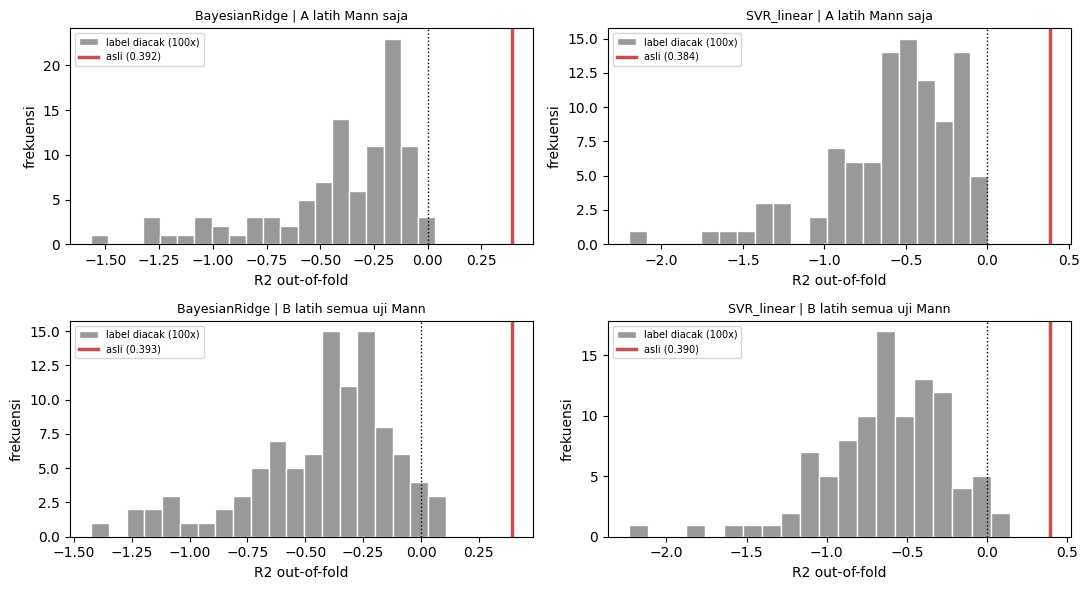

In [25]:
fig, ax = plt.subplots(len(SKENARIO), len(KANDIDAT), figsize=(11, 6), squeeze=False)
for r, sk in enumerate(SKENARIO):
    for c, nama in enumerate(KANDIDAT):
        a = ax[r][c]
        arr = np.array(acak[(nama, sk)])[:, 0]
        a.hist(arr, bins=20, color='#999999', edgecolor='white', label='label diacak (100x)')
        a.axvline(asli[(nama, sk)][0], color='#C44E52', lw=2.5, label=f'asli ({asli[(nama, sk)][0]:.3f})')
        a.axvline(0, color='k', lw=1, ls=':')
        a.set_title(f'{nama} | {sk.replace("_", " ")}', fontsize=9)
        a.set_xlabel('R2 out-of-fold'); a.set_ylabel('frekuensi')
        a.legend(fontsize=7)
plt.tight_layout()
plt.savefig(OUT / 'grafik_y_randomization_100.png', dpi=200, bbox_inches='tight')
plt.show()

# USP5 — Tanimoto Blend: Sebelum vs Sesudah Tambahan 27 Senyawa

**A:** latih dari subset Mann (53), evaluasi hanya fold Mann.

**B:** latih dari subset Mann + 27 senyawa lain (tanpa senyawa/scaffold uji), evaluasi pada fold Mann **yang sama**.

Menggunakan 3 seed, random 5-fold dan scaffold 5-fold.

In [31]:
import warnings, pickle
from pathlib import Path
import numpy as np, pandas as pd
from rdkit import Chem
from rdkit.Chem import rdFingerprintGenerator, MACCSkeys
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import KFold
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
warnings.filterwarnings('ignore', category=FutureWarning)

OUT = Path('hasil_skenario_80_uji_53/Tanimoto_Asli_53_vs_80')
OUT.mkdir(parents=True, exist_ok=True)
URL80 = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_pKd_80.csv'
URL53 = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv'
data80 = pd.read_csv(URL80)
data53 = pd.read_csv(URL53)
for d in [data80, data53]:
    d.columns = d.columns.str.strip()
    assert {'Molecule ChEMBL ID','Smiles','pKd'}.issubset(d.columns)
    d['pKd'] = pd.to_numeric(d['pKd'], errors='raise')
    d['canonical'] = d['Smiles'].map(lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s), canonical=True))
assert len(data80)==80 and len(data53)==53
assert data80.canonical.is_unique and data53.canonical.is_unique
assert set(data53.canonical).issubset(set(data80.canonical))
extra = data80[~data80.canonical.isin(data53.canonical)].copy()
assert len(extra)==27
# pKd untuk senyawa Mann selalu mengambil nilai dari file Mann 53.
df = pd.concat([data53, extra],ignore_index=True)
mols=[Chem.MolFromSmiles(s) for s in df.Smiles]
y=df.pKd.to_numpy(dtype=float)
groups=np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
print('53 Mann:',len(data53),'| tambahan:',len(extra),'| total:',len(df),'| scaffold Mann:',len(set(groups[:53])))
print('Output:', OUT)


53 Mann: 53 | tambahan: 27 | total: 80 | scaffold Mann: 25
Output: hasil_skenario_80_uji_53/Tanimoto_Asli_53_vs_80


In [32]:
# Tahap featurisasi: formula dan aturan seleksi bit persis seperti notebook asli Pak Ridwan.
def build_morgan(mols, radius=2, nbits=1024, min_count=4, counts=False):
    gen = rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=nbits)
    f = (lambda m: gen.GetCountFingerprintAsNumPy(m)) if counts else (lambda m: gen.GetFingerprintAsNumPy(m))
    F = np.array([f(m) for m in mols], dtype=float)
    mask = (F > 0).sum(0) >= min_count
    print(f"Morgan r={radius}: {nbits} bit -> {int(mask.sum())} bit aktif pada >= {min_count} molekul")
    return F[:, mask], mask

def build_maccs(mols):
    K = np.array([np.array(MACCSkeys.GenMACCSKeys(m)) for m in mols], dtype=float)
    mask = K.std(0) > 0
    print(f"MACCS: 167 key -> {int(mask.sum())} key informatif")
    return K[:, mask], mask

FP, FP_MASK = build_morgan(mols)
MACCS, MACCS_MASK = build_maccs(mols)
X_FPM = np.hstack([FP,MACCS])
X_BLEND = np.hstack([X_FPM,MACCS])
N_FPM = X_FPM.shape[1]
print('X_BLEND:',X_BLEND.shape, '| n_fpm:',N_FPM)


Morgan r=2: 1024 bit -> 137 bit aktif pada >= 4 molekul
MACCS: 167 key -> 121 key informatif
X_BLEND: (80, 379) | n_fpm: 258


In [37]:
def tanimoto_kernel(A, B):
    '''Kernel Tanimoto / MinMax. A:(n,p) B:(m,p) -> (n,m) di [0,1].'''
    inter = A @ B.T
    a = (A*A).sum(1)[:, None]
    b = (B*B).sum(1)[None, :]
    return inter / (a + b - inter + 1e-12)



In [38]:
class TanimotoBlend(BaseEstimator, RegressorMixin):
    '''
    Blend non-linear untuk pKd USP5.

    Input X diharapkan berupa [FP+MACCS | MACCS] yang digabung horizontal,
    dengan n_fpm = jumlah kolom bagian FP+MACCS.

    Anggota:
      1. SVR kernel Tanimoto pada FP+MACCS
      2. RandomForest pada FP+MACCS
      3. RandomForest pada MACCS
    Prediksi = rata-rata ketiganya, opsional dikalibrasi linear (nested).
    '''
    def __init__(self, n_fpm, C=5.0, epsilon=0.05, n_estimators=300, calibrate=False, random_state=0):
        self.n_fpm=n_fpm; self.C=C; self.epsilon=epsilon
        self.n_estimators=n_estimators; self.calibrate=calibrate; self.random_state=random_state

    def _views(self, X):
        return X[:, :self.n_fpm], X[:, self.n_fpm:]

    def fit(self, X, yy):
        F, M = self._views(X)
        self.F_ = F
        self.svr_ = SVR(kernel="precomputed", C=self.C, epsilon=self.epsilon).fit(tanimoto_kernel(F,F), yy)
        self.rf_fpm_ = RandomForestRegressor(self.n_estimators, random_state=self.random_state, n_jobs=-1).fit(F, yy)
        self.rf_maccs_ = RandomForestRegressor(self.n_estimators, random_state=self.random_state, n_jobs=-1).fit(M, yy)
        self.a_, self.b_ = 1.0, 0.0
        if self.calibrate:                      # nested: hanya memakai data training
            o = np.zeros(len(yy))
            for tr, te in KFold(5, shuffle=True, random_state=self.random_state).split(X):
                inner = TanimotoBlend(self.n_fpm, self.C, self.epsilon, self.n_estimators,
                                      calibrate=False, random_state=self.random_state).fit(X[tr], yy[tr])
                o[te] = inner.predict(X[te])
            self.a_, self.b_ = np.polyfit(o, yy, 1)
        return self

    def predict_members(self, X):
        F, M = self._views(X)
        return {"SVR-Tanimoto": self.svr_.predict(tanimoto_kernel(F, self.F_)),
                "RF (FP+MACCS)": self.rf_fpm_.predict(F),
                "RF (MACCS)":    self.rf_maccs_.predict(M)}

    def predict(self, X):
        p = np.mean(list(self.predict_members(X).values()), axis=0)
        return self.a_ * p + self.b_



In [39]:
SEEDS_VER_RAND = [700,701,702,703,704]
SEEDS_VER_SCAF = [800,801,802,803,804]
idx_mann = np.arange(53)
idx_all = np.arange(80)

def folds_random_mann(seed):
    return [(idx_mann[tr],idx_mann[te]) for tr,te in KFold(5,shuffle=True,random_state=seed).split(idx_mann)]

def folds_scaffold_mann(seed):
    # Persis algoritma pengalokasian scaffold notebook asli, diterapkan pada 53 Mann.
    unique_groups=np.unique(groups[idx_mann])
    perm=np.random.RandomState(seed).permutation(len(unique_groups))
    gmap={g: perm[i]%5 for i,g in enumerate(unique_groups)}
    f=np.array([gmap[g] for g in groups[idx_mann]])
    return [(idx_mann[f!=k],idx_mann[f==k]) for k in range(5) if (f==k).sum()>0]

def run_once(kind, seed, scenario, calibrate):
    folds = folds_random_mann(seed) if kind=='random' else folds_scaffold_mann(seed)
    preds = np.full(len(idx_mann),np.nan)
    train_counts=[]
    for train53, test53 in folds:
        if scenario=='A_Mann53':
            train=train53
        else:
            # Tambahan 27 senyawa boleh masuk train kecuali scaffold test (scaffold CV).
            train=np.r_[train53,np.arange(53,80)]
            if kind=='scaffold':
                train=train[~np.isin(groups[train], groups[test53])]
        # Audit ketat: tidak boleh ada struktur kimia yang identik antara train dan test.
        assert set(df.iloc[train].canonical).isdisjoint(set(df.iloc[test53].canonical))
        if kind=='scaffold':
            assert set(groups[train]).isdisjoint(set(groups[test53]))
        # Kelas dan hyperparameter persis notebook asli.
        model=TanimotoBlend(N_FPM, C=5.0, epsilon=0.05, n_estimators=300,
                            calibrate=calibrate, random_state=0)
        model.fit(X_BLEND[train],y[train])
        preds[test53]=model.predict(X_BLEND[test53])
        train_counts.append(len(train))
    assert np.isfinite(preds).all()
    truth=y[:53]
    score={'R2':r2_score(truth,preds),
           'RMSE':np.sqrt(mean_squared_error(truth,preds)),
           'MAE':mean_absolute_error(truth,preds)}
    return score,preds,train_counts


In [41]:
rows=[]; predicted=[]
for kind,seeds in [('random',SEEDS_VER_RAND),('scaffold',SEEDS_VER_SCAF)]:
    for cal in [False,True]:
        for seed in seeds:
            for scenario in ['A_Mann53','B_Mann53_plus27']:
                score,pred,ns = run_once(kind,seed,scenario,cal)
                rows.append(dict(protokol=kind,kalibrasi=cal,seed=seed,skenario=scenario,
                                 rata2_n_train=np.mean(ns),min_n_train=min(ns),max_n_train=max(ns),**score))
                predicted.extend(dict(protokol=kind,kalibrasi=cal,seed=seed,skenario=scenario,
                                      chembl_id=df.iloc[i]['Molecule ChEMBL ID'],
                                      smiles=df.iloc[i]['Smiles'],pKd_eksperimen=y[i],pKd_prediksi=pred[i])
                                 for i in range(53))
                print(f'{kind:8s} calibrate={cal!s:5s} seed={seed} {scenario:16s} R2={score["R2"]:.4f}')
results=pd.DataFrame(rows)
summary=results.groupby(['protokol','kalibrasi','skenario'])[['R2','RMSE','MAE']].agg(['mean','std']).round(4)
display(summary)
results.to_csv(OUT/'hasil_per_seed.csv',index=False)
pd.DataFrame(predicted).to_csv(OUT/'prediksi_oof_per_senyawa.csv',index=False)
summary.to_csv(OUT/'ringkasan_perbandingan.csv')
print('Hasil tersimpan:',OUT)


random   calibrate=False seed=700 A_Mann53         R2=0.4664
random   calibrate=False seed=700 B_Mann53_plus27  R2=0.4543
random   calibrate=False seed=701 A_Mann53         R2=0.3376
random   calibrate=False seed=701 B_Mann53_plus27  R2=0.3914
random   calibrate=False seed=702 A_Mann53         R2=0.4069
random   calibrate=False seed=702 B_Mann53_plus27  R2=0.4032
random   calibrate=False seed=703 A_Mann53         R2=0.3067
random   calibrate=False seed=703 B_Mann53_plus27  R2=0.3034
random   calibrate=False seed=704 A_Mann53         R2=0.3471
random   calibrate=False seed=704 B_Mann53_plus27  R2=0.3511
random   calibrate=True  seed=700 A_Mann53         R2=0.4440
random   calibrate=True  seed=700 B_Mann53_plus27  R2=0.4663
random   calibrate=True  seed=701 A_Mann53         R2=0.3306
random   calibrate=True  seed=701 B_Mann53_plus27  R2=0.3890
random   calibrate=True  seed=702 A_Mann53         R2=0.3547
random   calibrate=True  seed=702 B_Mann53_plus27  R2=0.3935
random   calibrate=True 

R2            RMSE             MAE  \
                                      mean     std    mean     std    mean   
protokol kalibrasi skenario                                                  
random   False     A_Mann53         0.3729  0.0636  0.3643  0.0188  0.2777   
                   B_Mann53_plus27  0.3807  0.0568  0.3621  0.0166  0.2736   
         True      A_Mann53         0.3425  0.0710  0.3730  0.0203  0.2855   
                   B_Mann53_plus27  0.3793  0.0612  0.3625  0.0180  0.2731   
scaffold False     A_Mann53         0.2289  0.0684  0.4041  0.0183  0.3099   
                   B_Mann53_plus27  0.2326  0.0660  0.4031  0.0176  0.3106   
         True      A_Mann53         0.1911  0.0698  0.4139  0.0184  0.3182   
                   B_Mann53_plus27  0.2267  0.0732  0.4046  0.0195  0.3099   

                                            
                                       std  
protokol kalibrasi skenario                 
random   False     A_Mann53         0.0115  
                   B_Mann53_plus27  0.0091  
         True      A_Mann53         0.0104  
                   B_Mann53_plus27  0.0099  
scaffold False     A_Mann53         0.0145  
                   B_Mann53_plus27  0.0112  
         True      A_Mann53         0.0174  
                   B_Mann53_plus27  0.0122

Hasil tersimpan: hasil_skenario_80_uji_53/Tanimoto_Asli_53_vs_80


# USP5 — GNN GraphConvModel pada 53 Senyawa Mann

Arsitektur mengikuti GraphConvModel USP5 sebelumnya: `graph_conv_layers=[64,64]`, `dense_layer_size=128`, `batch_size=10`, `learning_rate=0.001`, `dropout=0.0`, `batch_normalize=False`, dan **40 epoch**.

**Catatan:** Tidak menggunakan 27 senyawa tambahan.

In [4]:
import os, random, gc, tempfile
from pathlib import Path
import numpy as np
import pandas as pd
import tensorflow as tf
import deepchem as dc
from rdkit import Chem
from rdkit.Chem.Scaffolds import MurckoScaffold
from sklearn.model_selection import KFold, GroupKFold
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

OUT = Path('hasil_skenario_80_uji_53/GNN_GraphConv_53')
OUT.mkdir(parents=True, exist_ok=True)
print('DeepChem:', dc.__version__, '| TensorFlow:', tf.__version__)
print('Output:', OUT)


DeepChem: 2.8.0 | TensorFlow: 2.16.2
Output: hasil_skenario_80_uji_53/GNN_GraphConv_53


In [5]:
URL = 'https://raw.githubusercontent.com/aliyarahmaazizah/USP5/main/USP5_MANN_53.csv'
df = pd.read_csv(URL)
df.columns = df.columns.str.strip()
assert len(df) == 53, f'Diharapkan 53 baris, ditemukan {len(df)}'
assert {'Molecule ChEMBL ID', 'Smiles', 'pKd'}.issubset(df.columns)
df['pKd'] = pd.to_numeric(df['pKd'], errors='raise')
assert df['pKd'].notna().all()
mols = [Chem.MolFromSmiles(s) for s in df['Smiles']]
assert all(m is not None for m in mols), 'Ada SMILES tidak valid'
canonical = [Chem.MolToSmiles(m) for m in mols]
assert len(set(canonical)) == len(canonical), 'Ada duplikasi struktur'
y = df['pKd'].to_numpy(dtype=float)
groups = np.array([MurckoScaffold.MurckoScaffoldSmiles(mol=m) for m in mols])
assert len(set(groups)) >= 5
featurizer = dc.feat.ConvMolFeaturizer()
features = featurizer.featurize(df['Smiles'].tolist())
assert len(features) == 53 and all(f is not None for f in features)
print('Senyawa:', len(df), '| Scaffold unik:',len(set(groups)), '| Fitur graph valid:',len(features))


Senyawa: 53 | Scaffold unik: 25 | Fitur graph valid: 53


[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATION WARNING: please use GetValence(Chem.ValenceType.IMPLICIT) instead
[06:23:16] DEPRECATIO

In [6]:
SEED = 42
N_SPLITS = 5
EPOCHS = 40

def make_splits(kind):
    if kind == 'random':
        return list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(y))
    return list(GroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(np.zeros(len(y)), y, groups))

def dataset(idx):
    return dc.data.NumpyDataset(X=features[idx], y=y[idx].reshape(-1,1), ids=df['Molecule ChEMBL ID'].iloc[idx].to_numpy())

def evaluate(kind):
    pred = np.full(len(y), np.nan)
    fold_id = np.full(len(y), -1, dtype=int)
    details = []
    for fold,(tr,te) in enumerate(make_splits(kind),1):
        if kind == 'scaffold':
            assert set(groups[tr]).isdisjoint(set(groups[te]))
        tf.keras.backend.clear_session()
        random.seed(SEED + fold)
        np.random.seed(SEED + fold)
        tf.keras.utils.set_random_seed(SEED + fold)
        train_ds, test_ds = dataset(tr), dataset(te)
        # TemporaryDirectory mencegah model-model CV memenuhi /data.
        with tempfile.TemporaryDirectory(prefix=f'gnn_{kind}_{fold}_', dir=OUT) as model_path:
            model = dc.models.GraphConvModel(
                n_tasks=1, mode='regression',
                graph_conv_layers=[64,64], dense_layer_size=128,
                batch_size=10, learning_rate=0.001,
                dropout=0.0, batch_normalize=False,
                model_dir=model_path)
            model.fit(train_ds, nb_epoch=EPOCHS, checkpoint_interval=0)
            p = np.asarray(model.predict(test_ds)).reshape(-1)
            assert len(p) == len(te), 'Bentuk hasil prediksi tidak sesuai'
            pred[te] = p
            fold_id[te] = fold
            details.append({'metode':kind,'fold':fold,'n_train':len(tr),'n_valid':len(te),
                            'RMSE_fold':np.sqrt(mean_squared_error(y[te],p)),
                            'MAE_fold':mean_absolute_error(y[te],p)})
            del model, train_ds, test_ds
        gc.collect()
        print(f'{kind} fold {fold}/{N_SPLITS} selesai | train={len(tr)} valid={len(te)}', flush=True)
    assert np.isfinite(pred).all(), 'Ada prediksi kosong'
    score = {'model':'GNN GraphConvModel','metode':kind,'seed':SEED,
             'R2':r2_score(y,pred),
             'RMSE':np.sqrt(mean_squared_error(y,pred)),
             'MAE':mean_absolute_error(y,pred)}
    oof = pd.DataFrame({'Molecule ChEMBL ID':df['Molecule ChEMBL ID'],
                        'Smiles':df['Smiles'], 'pKd_eksperimen':y,
                        'pKd_prediksi':pred,'residual':y-pred,
                        'metode':kind,'seed':SEED,'fold':fold_id})
    return score,oof,pd.DataFrame(details)


In [7]:
scores, predictions, folds_detail = [], [], []
for kind in ['random','scaffold']:
    score,oof,detail = evaluate(kind)
    scores.append(score)
    predictions.append(oof)
    folds_detail.append(detail)
    print(f"{kind}: R²={score['R2']:.4f} | RMSE={score['RMSE']:.4f} | MAE={score['MAE']:.4f}")

results = pd.DataFrame(scores)
results.to_csv(OUT/'GNN53_hasil_CV_seed42.csv', index=False)
pd.concat(predictions,ignore_index=True).to_csv(OUT/'GNN53_prediksi_OOF_seed42.csv',index=False)
pd.concat(folds_detail,ignore_index=True).to_csv(OUT/'GNN53_detail_fold_seed42.csv',index=False)
display(results)
print('Output disimpan di:', OUT)


2026-11-10 06:24:29.037949: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1928] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31132 MB memory:  -> device: 0, name: Tesla V100-SXM2-32GB, pci bus id: 0000:0b:00.0, compute capability: 7.0


random fold 1/5 selesai | train=42 valid=11
random fold 2/5 selesai | train=42 valid=11
random fold 3/5 selesai | train=42 valid=11
random fold 4/5 selesai | train=43 valid=10
random fold 5/5 selesai | train=43 valid=10
random: R²=0.2583 | RMSE=0.3966 | MAE=0.3113
scaffold fold 1/5 selesai | train=48 valid=5
scaffold fold 2/5 selesai | train=46 valid=7
scaffold fold 3/5 selesai | train=26 valid=27
scaffold fold 4/5 selesai | train=46 valid=7
scaffold fold 5/5 selesai | train=46 valid=7
scaffold: R²=0.2139 | RMSE=0.4083 | MAE=0.3393


,model,metode,seed,R2,RMSE,MAE
0,GNN GraphConvModel,random,42,0.258252,0.396635,0.311321
1,GNN GraphConvModel,scaffold,42,0.213940,0.408311,0.339277


Output disimpan di: hasil_skenario_80_uji_53/GNN_GraphConv_53


In [1]:
import os

print("Legacy Keras:", os.environ.get("TF_USE_LEGACY_KERAS"))

Legacy Keras: 1


In [2]:
import tensorflow as tf
import tf_keras
import deepchem as dc

optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=0.001)

print("TensorFlow:", tf.__version__)
print("DeepChem:", dc.__version__)
print("Optimizer berhasil:", type(optimizer).__name__)

2026-11-10 06:20:49.752100: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-10 06:20:49.777065: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2026-11-10 06:20:49.777099: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1442] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2026-11-10 06:20:49.797380: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
No normalization for SPS. Feature removed!
No normal

Instructions for updating:
experimental_relax_shapes is deprecated, use reduce_retracing instead


Skipped loading modules with pytorch-geometric dependency, missing a dependency. No module named 'torch_geometric'
Skipped loading modules with transformers dependency. No module named 'transformers'
cannot import name 'HuggingFaceModel' from 'deepchem.models.torch_models' (/data/Aliya/usp5_env_baru/lib/python3.10/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-geometric dependency, missing a dependency. cannot import name 'DMPNN' from 'deepchem.models.torch_models' (/data/Aliya/usp5_env_baru/lib/python3.10/site-packages/deepchem/models/torch_models/__init__.py)
Skipped loading modules with pytorch-lightning dependency, missing a dependency. No module named 'lightning'
Skipped loading some Jax models, missing a dependency. No module named 'jax'


TensorFlow: 2.16.2
DeepChem: 2.8.0
Optimizer berhasil: Adam
